# LOCAL notebook – Cluster E: Team 17 (OpenMP/Pthreads) + Team 18 (MPI) + Team 20 CPU runs
**Run every cell of THIS notebook on your own PC (Jupyter / VS Code), top to bottom.** The GPU part (Team 19) and the final Team 20 analysis are in the second notebook, `NBody_COLAB_...ipynb`, which you run in Google Colab.

**Needs:** Linux, or Windows with WSL2, or macOS with `gcc` + `open-mpi` (`brew install gcc open-mpi`; then use `g++-14` instead of `g++` in B2/B4). On Ubuntu/WSL: `sudo apt install g++ openmpi-bin libopenmpi-dev python3-pip` and `pip install pandas matplotlib numpy`.

| Part | What | Output |
|---|---|---|
| A | setup + shared header | – |
| B | Team 17: seq, OpenMP, Pthreads (100-step benchmark) | `results/team17.csv`, charts |
| C | Team 18: MPI allgather / ring / overlap (100 steps; 1–16 ranks) | `results/team18*.csv`, charts |
| E | Team 20: 10,000-step accuracy runs of seq, OpenMP, MPI in FP64/FP32/mixed | `acc/` |
| – | pack results | **`local_results.zip` → upload to Colab** |

**Settings from the brief:** performance runs = 100 steps; accuracy runs = 10,000 steps; N = 4,096 – 65,536 on the CPU; verification limit 1e-5 on the first step; fixed seed 42 and fixed dt = 1e-3.
**Time:** roughly 1–2 hours in total on a 4–8 core PC (the N = 65,536 runs are the slow ones – delete `65536` from the size list in B5 to save ~45 min).

🖥️ **[RUN ON YOUR LOCAL PC]**  **A1 – setup** (run once)

In [1]:
import os
os.makedirs('nbody_work/results', exist_ok=True); os.chdir('nbody_work')       # everything is created inside nbody_work/
# let MPI run more ranks than you have cores (needed for the 16-rank runs)
os.environ.update(OMPI_ALLOW_RUN_AS_ROOT='1', OMPI_ALLOW_RUN_AS_ROOT_CONFIRM='1', OMPI_MCA_rmaps_base_oversubscribe='1')
print('working dir:', os.getcwd())

working dir: c:\Users\johnf\Downloads\map code\nbody_work


In [25]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: c:\Users\johnf\Downloads\map code\nbody_work
Files here: ['nbody_common.hpp', 'nbody_smp', 'nbody_smp.cpp', 'results']


In [26]:
import sys
print(sys.executable)
print(sys.platform)

c:\diyyy\programs\python progs\python.exe
win32


In [27]:
import subprocess
import os

env = os.environ.copy()
env.update({
    "TERM": "dumb",
    "COLUMNS": "120",
    "LINES": "40"
})

result = subprocess.run(
    ["wsl", "bash", "-lc", "whoami && pwd && g++ --version | head -1"],
    capture_output=True,
    text=True,
    env=env
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0
anil
/mnt/c/Users/johnf/Downloads/map code/nbody_work
g++ (Ubuntu 11.4.0-1ubuntu1~22.04.3) 11.4.0

your 131072x1 screen size is bogus. expect trouble
your 131072x1 screen size is bogus. expect trouble



In [28]:
import subprocess

cmd = "echo 'WSL benchmark environment ready'; pwd; nproc"

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

WSL benchmark environment ready
/mnt/c/Users/johnf/Downloads/map code/nbody_work
16

your 131072x1 screen size is bogus. expect trouble
your 131072x1 screen size is bogus. expect trouble



In [29]:
import subprocess

cmd = """
unset TERMCAP
export TERM=dumb
export COLUMNS=120
export LINES=40
echo "Terminal configured"
"""

result = subprocess.run(
    ["wsl", "bash", "-c", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Terminal configured




In [30]:
import os
import subprocess

def run_wsl(command):
    env = os.environ.copy()
    env.update({
        "TERM": "dumb",
        "COLUMNS": "120",
        "LINES": "40"
    })

    return subprocess.run(
        ["wsl", "bash", "-c", command],
        env=env,
        text=True,
        check=True
    )

In [31]:
run_wsl("echo 'WSL ready'; nproc; g++ --version | head -1")

CompletedProcess(args=['wsl', 'bash', '-c', "echo 'WSL ready'; nproc; g++ --version | head -1"], returncode=0)

🖥️ **[RUN ON YOUR LOCAL PC]**  **A2 – check your tools and core count**

In [32]:
import subprocess
import os

env = os.environ.copy()
env.update({"TERM": "dumb", "COLUMNS": "120", "LINES": "40"})

cmd = """
g++ --version | head -1
mpicxx --version | head -1
mpirun --version | head -1
echo "cores on this PC: $(nproc)   <- use this when you set THREADS in B5"
"""

subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    env=env,
    check=True
)

CompletedProcess(args=['wsl', 'bash', '-lc', '\ng++ --version | head -1\nmpicxx --version | head -1\nmpirun --version | head -1\necho "cores on this PC: $(nproc)   <- use this when you set THREADS in B5"\n'], returncode=0)

🖥️ **[RUN ON YOUR LOCAL PC]**  **A3 – shared header** (identical file is used in Colab)

In [33]:
%%writefile nbody_common.hpp
// =============================================================================
//  nbody_common.hpp  --  shared by Team 17 (OpenMP/Pthreads), Team 18 (MPI),
//  Team 19 (CUDA) and used by Team 20 (precision study).
//
//  EVERY platform uses exactly the same:
//    * physics   : softened gravity, G = 1, eps = 0.05, masses m_i = 1/N
//    * initial conditions : deterministic RNG (seed 42) -> identical on all platforms
//    * integrator: velocity-Verlet (kick-drift-kick), dt = 1e-3
//    * output    : results CSV (common course format), energy CSV, trajectory file
//
//  Precision modes (template "Mode" types):
//      fp64  : state S=double, pair-force arithmetic F=double
//      fp32  : state S=float , pair-force arithmetic F=float
//      mixed : state S=double, pair-force arithmetic F=float, accumulation in double
//              (dx = xj-xi is formed in double, THEN cast to float; the float pair
//               force is added to a double accumulator)
//  Diagnostics (energy, verification) are ALWAYS computed in FP64.
// =============================================================================
#pragma once
#include <cstdio>
#include <cstdlib>
#include <cstdint>
#include <cstring>
#include <cmath>
#include <vector>
#include <string>
#include <chrono>
#include <algorithm>

#if defined(__CUDACC__)
  #define NB_PRAGMA(x)
#else
  #define NB_PRAGMA(x) _Pragma(x)
#endif

namespace nb {

// ----------------------------- physics constants ----------------------------
constexpr double G    = 1.0;
constexpr double EPS2 = 0.05 * 0.05;   // softening length squared
constexpr double DT   = 1.0e-3;        // fixed time step
constexpr double V0   = 0.5;           // initial velocity half-range
constexpr uint64_t SEED = 42;

// ----------------------------- precision modes ------------------------------
struct M64  { typedef double S; typedef double F; static const char* name() { return "fp64";  } };
struct M32  { typedef float  S; typedef float  F; static const char* name() { return "fp32";  } };
struct MMix { typedef double S; typedef float  F; static const char* name() { return "mixed"; } };

inline std::string lower(std::string s) { for (auto& c : s) c = (char)tolower(c); return s; }

// ----------------------------- timing ---------------------------------------
inline double now_ms() {
    using namespace std::chrono;
    return duration<double, std::milli>(steady_clock::now().time_since_epoch()).count();
}

// ----------------------------- argument parsing -----------------------------
struct Args {
    std::vector<std::pair<std::string, std::string>> kv;
    Args(int argc, char** argv) {
        for (int i = 1; i < argc; ++i) {
            std::string k = argv[i];
            if (k.rfind("--", 0) == 0) {
                k = k.substr(2);
                std::string v = "1";
                if (i + 1 < argc && strncmp(argv[i + 1], "--", 2) != 0) v = argv[++i];
                kv.push_back({k, v});
            }
        }
    }
    bool has(const std::string& k) const { for (auto& p : kv) if (p.first == k) return true; return false; }
    std::string str(const std::string& k, const std::string& d) const { for (auto& p : kv) if (p.first == k) return p.second; return d; }
    int    i(const std::string& k, int d)    const { return has(k) ? atoi(str(k, "").c_str()) : d; }
    double d(const std::string& k, double dv) const { return has(k) ? atof(str(k, "").c_str()) : dv; }
};

// ----------------------------- initial conditions ---------------------------
struct Particles {
    int n = 0;
    std::vector<double> x, y, z, vx, vy, vz, m;
};

inline uint64_t splitmix64(uint64_t& s) {
    uint64_t z = (s += 0x9E3779B97F4A7C15ULL);
    z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9ULL;
    z = (z ^ (z >> 27)) * 0x94D049BB133111EBULL;
    return z ^ (z >> 31);
}
inline double u01(uint64_t& s) { return (double)(splitmix64(s) >> 11) * (1.0 / 9007199254740992.0); }

// positions uniform in [-1,1]^3, velocities uniform in [-V0,V0]^3, m = 1/N.
inline Particles make_ic(int n, uint64_t seed = SEED) {
    Particles p; p.n = n;
    p.x.resize(n); p.y.resize(n); p.z.resize(n);
    p.vx.resize(n); p.vy.resize(n); p.vz.resize(n); p.m.assign(n, 1.0 / n);
    uint64_t s = seed;
    for (int i = 0; i < n; ++i) {
        p.x[i]  = 2.0 * u01(s) - 1.0;  p.y[i]  = 2.0 * u01(s) - 1.0;  p.z[i]  = 2.0 * u01(s) - 1.0;
        p.vx[i] = V0 * (2.0 * u01(s) - 1.0);
        p.vy[i] = V0 * (2.0 * u01(s) - 1.0);
        p.vz[i] = V0 * (2.0 * u01(s) - 1.0);
    }
    return p;
}

// ----------------------------- the force kernel (host) ----------------------
// Adds to (ax,ay,az) the acceleration on particle i (position xi,yi,zi) caused by
// the nj source particles xj,yj,zj,mj.  Self-interaction is harmless (dx=0).
template <class M>
inline void accel_one(typename M::S xi, typename M::S yi, typename M::S zi, int nj,
                      const typename M::S* xj, const typename M::S* yj, const typename M::S* zj,
                      const typename M::S* mj,
                      typename M::S& ax, typename M::S& ay, typename M::S& az) {
    typedef typename M::S S; typedef typename M::F F;
    S sx = 0, sy = 0, sz = 0;
    NB_PRAGMA("omp simd reduction(+:sx,sy,sz)")
    for (int j = 0; j < nj; ++j) {
        F dx = (F)(xj[j] - xi), dy = (F)(yj[j] - yi), dz = (F)(zj[j] - zi);
        F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
        F inv = (F)1 / std::sqrt(r2);
        F s   = (F)mj[j] * (inv * inv * inv);
        sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
    }
    ax += sx; ay += sy; az += sz;
}

// ----------------------------- FP64 diagnostics -----------------------------
struct Energy { double ke, pe, etot; };

inline Energy energy(const Particles& p) {
    const int n = p.n;
    double ke = 0, pe = 0;
    for (int i = 0; i < n; ++i) ke += 0.5 * p.m[i] * (p.vx[i]*p.vx[i] + p.vy[i]*p.vy[i] + p.vz[i]*p.vz[i]);
    for (int i = 0; i < n; ++i) {
        double s = 0;
        NB_PRAGMA("omp simd reduction(+:s)")
        for (int j = i + 1; j < n; ++j) {
            double dx = p.x[j]-p.x[i], dy = p.y[j]-p.y[i], dz = p.z[j]-p.z[i];
            s += p.m[j] / std::sqrt(dx*dx + dy*dy + dz*dz + EPS2);
        }
        pe -= G * p.m[i] * s;
    }
    return {ke, pe, ke + pe};
}

// Reference accelerations: sequential, FP64.
inline void ref_accel(const Particles& p, std::vector<double>& ax, std::vector<double>& ay, std::vector<double>& az) {
    const int n = p.n;
    ax.assign(n, 0); ay.assign(n, 0); az.assign(n, 0);
    for (int i = 0; i < n; ++i)
        accel_one<M64>(p.x[i], p.y[i], p.z[i], n, p.x.data(), p.y.data(), p.z.data(), p.m.data(), ax[i], ay[i], az[i]);
}

// max over particles of |a - a_ref| / |a_ref|
inline double max_rel_force_error(const std::vector<double>& ax, const std::vector<double>& ay, const std::vector<double>& az,
                                  const std::vector<double>& rx, const std::vector<double>& ry, const std::vector<double>& rz) {
    double worst = 0;
    for (size_t i = 0; i < ax.size(); ++i) {
        double ex = ax[i]-rx[i], ey = ay[i]-ry[i], ez = az[i]-rz[i];
        double num = std::sqrt(ex*ex + ey*ey + ez*ez);
        double den = std::sqrt(rx[i]*rx[i] + ry[i]*ry[i] + rz[i]*rz[i]);
        worst = std::max(worst, num / (den > 0 ? den : 1.0));
    }
    return worst;
}

// ----------------------------- results CSV (course format) ------------------
inline void csv_row(const std::string& path, int problem, const std::string& platform, const std::string& impl,
                    const std::string& dataset, int size, int par, int run_id,
                    double total_ms, double kernel_ms, double transfer_ms, double thr, double err) {
    bool exists = false;
    if (FILE* t = fopen(path.c_str(), "r")) { fseek(t, 0, SEEK_END); exists = ftell(t) > 0; fclose(t); }
    FILE* f = fopen(path.c_str(), "a");
    if (!f) { fprintf(stderr, "cannot open %s\n", path.c_str()); return; }
    if (!exists) fprintf(f, "cluster,problem,platform,implementation,dataset,size,threads_or_ranks,run_id,total_ms,kernel_ms,transfer_ms,throughput,error,power_w\n");
    char e[64] = ""; if (err >= 0) snprintf(e, sizeof e, "%.3e", err);
    fprintf(f, "E,%d,%s,%s,%s,%d,%d,%d,%.6f,%.6f,%.6f,%.6e,%s,\n", problem, platform.c_str(), impl.c_str(),
            dataset.c_str(), size, par, run_id, total_ms, kernel_ms, transfer_ms, thr, e);
    fclose(f);
}

// ----------------------------- the driver -----------------------------------
// A "Sim" backend must provide:
//   bool is_root(); std::string impl(); int par();
//   void load(const Particles&);      // set state + compute initial accelerations, reset timers
//   void advance(int steps);          // velocity-Verlet steps
//   void sync(); void finalize();     // barrier / copy-back (finalize = timed D2H for GPU)
//   Timing timing();                  // kernel_ms<0 means "same as step wall time"
//   bool gather(Particles&);          // full FP64 state on root (returns true on root)
//   bool gather_accel(vector<double>&,vector<double>&,vector<double>&);
//   std::string notes();
struct Timing { double kernel_ms = -1, transfer_ms = 0, extra_ms = 0; };

template <class Sim>
int drive(Sim& sim, const Args& a, int problem, const std::string& platform, const char* prec_name) {
    const int n = a.i("n", 4096), steps = a.i("steps", 100), runs = a.i("runs", 5);
    const int eevery = a.i("energy-every", 0);
    const std::string csv = a.str("csv", "results.csv"), out = a.str("out", "run");
    const bool root = sim.is_root();
    const std::string impl = sim.impl();
    Particles ic = make_ic(n);

    // ---- first-step verification against the sequential FP64 reference ----
    double err = -1;
    if (a.i("verify", 1) && n <= a.i("verify-max", 65536)) {
        sim.load(ic);
        std::vector<double> ax, ay, az;
        bool r = sim.gather_accel(ax, ay, az);
        if (r) {
            std::vector<double> rx, ry, rz; ref_accel(ic, rx, ry, rz);
            err = max_rel_force_error(ax, ay, az, rx, ry, rz);
            printf("VERIFY  impl=%s  N=%d  max_rel_force_error_vs_seq_fp64 = %.3e\n", impl.c_str(), n, err);
        }
    }

    if (eevery <= 0) {
        // ------------------------- performance mode -------------------------
        std::vector<double> tot, thr;
        for (int r = 0; r <= runs; ++r) {            // r = 0 is the warm-up run (discarded)
            sim.load(ic); sim.sync();
            double t0 = now_ms();
            sim.advance(steps);
            sim.sync();
            double step_ms = now_ms() - t0;
            sim.finalize();
            Timing t = sim.timing();
            double total = step_ms + t.extra_ms;
            double kern  = t.kernel_ms >= 0 ? t.kernel_ms : step_ms - t.transfer_ms;
            double ips   = (double)n * n * steps / (step_ms * 1e-3);   // N^2 pair interactions / s
            if (r > 0 && root) {
                csv_row(csv, problem, platform, impl, "gravity_steps" + std::to_string(steps), n, sim.par(), r, total, kern, t.transfer_ms, ips, err);
                tot.push_back(total); thr.push_back(ips);
            }
        }
        if (root) {
            double mt = 0, mi = 0; for (double v : tot) mt += v; for (double v : thr) mi += v;
            mt /= tot.size(); mi /= thr.size();
            double st = 0, si = 0; for (double v : tot) st += (v-mt)*(v-mt); for (double v : thr) si += (v-mi)*(v-mi);
            st = std::sqrt(st / std::max<size_t>(1, tot.size()-1)); si = std::sqrt(si / std::max<size_t>(1, thr.size()-1));
            printf("RESULT  %-28s N=%-7d steps=%-5d par=%-3d total_ms=%.2f+-%.2f  Ginteractions/s=%.4f+-%.4f  GFLOP/s(20 flop/int)=%.2f  [%d timed runs]\n",
                   impl.c_str(), n, steps, sim.par(), mt, st, mi/1e9, si/1e9, 20.0*mi/1e9, (int)tot.size());
            std::string nt = sim.notes(); if (!nt.empty()) printf("NOTES   %s\n", nt.c_str());
            printf("CSV rows appended to %s\n", csv.c_str());
        }
        return 0;
    }

    // ------------------------- accuracy / energy mode -----------------------
    sim.load(ic);
    FILE* fe = nullptr; std::vector<double> snaps; int nsnap = 0; double E0 = 0, maxdrift = 0, adv_ms = 0;
    if (root) { fe = fopen((out + "_energy.csv").c_str(), "w"); fprintf(fe, "step,time,ke,pe,etot,rel_drift\n"); }
    auto sample = [&](int step) {
        Particles s; if (!sim.gather(s)) return;
        Energy e = energy(s);
        if (step == 0) E0 = e.etot;
        double drift = (e.etot - E0) / std::fabs(E0); maxdrift = std::max(maxdrift, std::fabs(drift));
        fprintf(fe, "%d,%.9g,%.17g,%.17g,%.17g,%.6e\n", step, step * DT, e.ke, e.pe, e.etot, drift);
        snaps.insert(snaps.end(), s.x.begin(), s.x.end());
        snaps.insert(snaps.end(), s.y.begin(), s.y.end());
        snaps.insert(snaps.end(), s.z.begin(), s.z.end());
        ++nsnap;
    };
    sample(0);
    for (int s = 0; s < steps; s += eevery) {
        int k = std::min(eevery, steps - s);
        sim.sync(); double t0 = now_ms();
        sim.advance(k);
        sim.sync(); adv_ms += now_ms() - t0;
        sample(s + k);
    }
    if (root) {
        fclose(fe);
        FILE* ft = fopen((out + "_traj.bin").c_str(), "wb");      // header: int64 n, int64 nsnap; then nsnap*(x[n],y[n],z[n]) doubles
        int64_t h[2] = {n, nsnap}; fwrite(h, sizeof(int64_t), 2, ft);
        fwrite(snaps.data(), sizeof(double), snaps.size(), ft); fclose(ft);
        double ips = (double)n * n * steps / (adv_ms * 1e-3);
        csv_row(csv, problem, platform, impl, "accuracy_steps" + std::to_string(steps), n, sim.par(), 1, adv_ms, adv_ms, 0, ips, err);
        printf("ACCURACY impl=%s N=%d steps=%d  advance_time=%.1f ms  Ginteractions/s=%.4f  max|dE/E0|=%.3e\n",
               impl.c_str(), n, steps, adv_ms, ips / 1e9, maxdrift);
        printf("wrote %s_energy.csv and %s_traj.bin\n", out.c_str(), out.c_str());
    }
    (void)prec_name;
    return 0;
}

}  // namespace nb

Overwriting nbody_common.hpp


🖥️ **[RUN ON YOUR LOCAL PC]**


## Part B – Team 17 · Problem 17 · Shared-memory N-body
**Variants** (`--variant`): `seq`, `seq_aos` (sequential baselines, SoA vs AoS) · `omp_full` (OpenMP over particles, full force per particle) · `omp_full_aos` · `omp_sym_priv` (Newton's 3rd law + per-thread private buffers + reduction) · `omp_sym_atomic` (Newton's 3rd law + `omp atomic`) · `pthreads` (Pthreads version of `omp_full`) · `pthreads_sym` (Pthreads version of `omp_sym_priv`, the fastest OpenMP variant - the brief asks for Pthreads of the *best* OpenMP variant).
Not included: the *optional* Barnes–Hut tree code.

Steps: **B1** write code → **B2** compile → **B3** verify → **B4** vectorisation report → **B5** benchmark sweep → **B6** summary table → **B7** charts (speedup, efficiency, symmetry effect, data layout).

🖥️ **[RUN ON YOUR LOCAL PC]**  **B1 – source code**

In [34]:
%%writefile nbody_smp.cpp
// =============================================================================
//  Team 17 / Problem 17 : Shared-memory N-body  (sequential, OpenMP, Pthreads)
//
//  variants (--variant):
//    seq             sequential all-pairs, structure-of-arrays (SoA)   <- baseline
//    seq_aos         sequential, array-of-structures layout
//    omp_full        OpenMP over particles, each thread computes the FULL force on its own particles (SoA)
//    omp_full_aos    same, AoS layout
//    omp_sym_priv    Newton's 3rd law, per-thread private force buffers + reduction
//    omp_sym_atomic  Newton's 3rd law, '#pragma omp atomic' updates
//    pthreads        Pthreads version of omp_full (row blocks, create/join every force evaluation)
//    pthreads_sym    Pthreads version of omp_sym_priv (the fastest OpenMP variant): Newton's 3rd law,
//                    per-thread private buffers, 2nd create/join phase does the reduction
//  precision (--prec): fp64 | fp32 | mixed
// =============================================================================
#include "nbody_common.hpp"
#include <omp.h>
#include <pthread.h>

using namespace nb;

template <class S> struct Body { S x, y, z, m; };

template <class M>
struct SmpSim {
    typedef typename M::S S; typedef typename M::F F;
    int n, T; std::string variant; bool use_omp;
    std::vector<S> x, y, z, vx, vy, vz, m, ax, ay, az, priv;
    std::vector<Body<S>> aos;
    std::vector<double> md;
    double t_create = 0, t_join = 0;

    SmpSim(int n_, int T_, const std::string& v) : n(n_), T(T_), variant(v) {
        static const char* ok[] = {"seq","seq_aos","omp_full","omp_full_aos","omp_sym_priv","omp_sym_atomic","pthreads","pthreads_sym"};
        bool found = false; for (auto s : ok) if (v == s) found = true;
        if (!found) { fprintf(stderr, "unknown variant '%s'\n", v.c_str()); exit(1); }
        use_omp = v.rfind("omp", 0) == 0;
        x.resize(n); y.resize(n); z.resize(n); vx.resize(n); vy.resize(n); vz.resize(n); m.resize(n);
        ax.resize(n); ay.resize(n); az.resize(n);
        if (v == "seq_aos" || v == "omp_full_aos") aos.resize(n);
        if (v == "omp_sym_priv" || v == "pthreads_sym") priv.resize((size_t)T * 3 * n);
    }
    bool is_root() const { return true; }
    std::string impl() const { return variant + "_" + M::name(); }
    int par() const { return T; }
    void sync() {}
    void finalize() {}
    Timing timing() { return Timing(); }
    std::string notes() {
        if (variant.rfind("pthreads", 0) != 0) return "";
        char b[160]; snprintf(b, sizeof b, "pthreads: total thread-create time %.3f ms, total join/wait time %.3f ms (last run)", t_create, t_join);
        return b;
    }

    void load(const Particles& ic) {
        for (int i = 0; i < n; ++i) {
            x[i] = (S)ic.x[i]; y[i] = (S)ic.y[i]; z[i] = (S)ic.z[i];
            vx[i] = (S)ic.vx[i]; vy[i] = (S)ic.vy[i]; vz[i] = (S)ic.vz[i]; m[i] = (S)ic.m[i];
        }
        md = ic.m;
        compute_forces();
        t_create = t_join = 0;
    }

    // ---------------- force kernels ----------------
    void range_full(int i0, int i1) {                         // SoA, full force on particles [i0,i1)
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        for (int i = i0; i < i1; ++i) {
            S a = 0, b = 0, c = 0;
            accel_one<M>(X[i], Y[i], Z[i], n, X, Y, Z, Mm, a, b, c);
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    void forces_full_soa(bool par) {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        #pragma omp parallel for schedule(static) num_threads(T) if(par)
        for (int i = 0; i < n; ++i) {
            S a = 0, b = 0, c = 0;
            accel_one<M>(X[i], Y[i], Z[i], n, X, Y, Z, Mm, a, b, c);
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    void forces_full_aos(bool par) {
        for (int i = 0; i < n; ++i) aos[i] = Body<S>{x[i], y[i], z[i], m[i]};   // O(N) repack (negligible vs O(N^2))
        const Body<S>* B = aos.data();
        #pragma omp parallel for schedule(static) num_threads(T) if(par)
        for (int i = 0; i < n; ++i) {
            S xi = B[i].x, yi = B[i].y, zi = B[i].z, sx = 0, sy = 0, sz = 0;
            #pragma omp simd reduction(+:sx,sy,sz)
            for (int j = 0; j < n; ++j) {
                F dx = (F)(B[j].x - xi), dy = (F)(B[j].y - yi), dz = (F)(B[j].z - zi);
                F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                F inv = (F)1 / std::sqrt(r2);
                F s   = (F)B[j].m * (inv * inv * inv);
                sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
            }
            ax[i] = sx; ay[i] = sy; az[i] = sz;
        }
    }
    void forces_sym_priv() {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        #pragma omp parallel num_threads(T)
        {
            const int t = omp_get_thread_num(), nt = omp_get_num_threads();
            S* bx = priv.data() + (size_t)t * 3 * n; S* by = bx + n; S* bz = by + n;
            for (int i = 0; i < 3 * n; ++i) bx[i] = 0;                      // own buffer only -> no race
            #pragma omp for schedule(dynamic, 8)                           // triangular loop -> dynamic
            for (int i = 0; i < n - 1; ++i) {
                S xi = X[i], yi = Y[i], zi = Z[i], mi = Mm[i], sx = 0, sy = 0, sz = 0;
                #pragma omp simd reduction(+:sx,sy,sz)
                for (int j = i + 1; j < n; ++j) {
                    F dx = (F)(X[j] - xi), dy = (F)(Y[j] - yi), dz = (F)(Z[j] - zi);
                    F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                    F inv = (F)1 / std::sqrt(r2);
                    F s   = inv * inv * inv;
                    F fx = s * dx, fy = s * dy, fz = s * dz;
                    sx += (S)((F)Mm[j] * fx); sy += (S)((F)Mm[j] * fy); sz += (S)((F)Mm[j] * fz);
                    bx[j] -= (S)((F)mi * fx); by[j] -= (S)((F)mi * fy); bz[j] -= (S)((F)mi * fz);
                }
                bx[i] += sx; by[i] += sy; bz[i] += sz;
            }                                                              // implicit barrier
            #pragma omp for schedule(static)
            for (int i = 0; i < n; ++i) {                                  // reduction over thread buffers
                S a = 0, b = 0, c = 0;
                for (int q = 0; q < nt; ++q) {
                    const S* p = priv.data() + (size_t)q * 3 * n;
                    a += p[i]; b += p[n + i]; c += p[2 * n + i];
                }
                ax[i] = a; ay[i] = b; az[i] = c;
            }
        }
    }
    void forces_sym_atomic() {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        S *AX = ax.data(), *AY = ay.data(), *AZ = az.data();
        for (int i = 0; i < n; ++i) { AX[i] = 0; AY[i] = 0; AZ[i] = 0; }
        #pragma omp parallel for schedule(dynamic, 8) num_threads(T)
        for (int i = 0; i < n - 1; ++i) {
            S xi = X[i], yi = Y[i], zi = Z[i], mi = Mm[i], sx = 0, sy = 0, sz = 0;
            for (int j = i + 1; j < n; ++j) {
                F dx = (F)(X[j] - xi), dy = (F)(Y[j] - yi), dz = (F)(Z[j] - zi);
                F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                F inv = (F)1 / std::sqrt(r2);
                F s   = inv * inv * inv;
                F fx = s * dx, fy = s * dy, fz = s * dz;
                sx += (S)((F)Mm[j] * fx); sy += (S)((F)Mm[j] * fy); sz += (S)((F)Mm[j] * fz);
                S ux = (S)((F)mi * fx), uy = (S)((F)mi * fy), uz = (S)((F)mi * fz);
                #pragma omp atomic
                AX[j] -= ux;
                #pragma omp atomic
                AY[j] -= uy;
                #pragma omp atomic
                AZ[j] -= uz;
            }
            #pragma omp atomic
            AX[i] += sx;
            #pragma omp atomic
            AY[i] += sy;
            #pragma omp atomic
            AZ[i] += sz;
        }
    }
    struct Job { SmpSim* s; int i0, i1; };
    static void* worker(void* p) { Job* j = (Job*)p; j->s->range_full(j->i0, j->i1); return nullptr; }
    void forces_pthreads() {
        std::vector<pthread_t> th(T); std::vector<Job> jobs(T);
        double t0 = now_ms();
        for (int t = 0; t < T; ++t) {
            jobs[t] = Job{this, (int)((long)n * t / T), (int)((long)n * (t + 1) / T)};
            pthread_create(&th[t], nullptr, &SmpSim::worker, &jobs[t]);
        }
        double t1 = now_ms();
        for (int t = 0; t < T; ++t) pthread_join(th[t], nullptr);
        double t2 = now_ms();
        t_create += t1 - t0; t_join += t2 - t1;
    }
    // ---- pthreads_sym: thread t takes rows t, t+T, t+2T... (round-robin balances the triangular loop) ----
    void sym_rows(int t) {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        S* bx = priv.data() + (size_t)t * 3 * n; S* by = bx + n; S* bz = by + n;
        for (int i = 0; i < 3 * n; ++i) bx[i] = 0;                         // own buffer only -> no race
        for (int i = t; i < n - 1; i += T) {
            S xi = X[i], yi = Y[i], zi = Z[i], mi = Mm[i], sx = 0, sy = 0, sz = 0;
            #pragma omp simd reduction(+:sx,sy,sz)
            for (int j = i + 1; j < n; ++j) {
                F dx = (F)(X[j] - xi), dy = (F)(Y[j] - yi), dz = (F)(Z[j] - zi);
                F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                F inv = (F)1 / std::sqrt(r2);
                F s   = inv * inv * inv;
                F fx = s * dx, fy = s * dy, fz = s * dz;
                sx += (S)((F)Mm[j] * fx); sy += (S)((F)Mm[j] * fy); sz += (S)((F)Mm[j] * fz);
                bx[j] -= (S)((F)mi * fx); by[j] -= (S)((F)mi * fy); bz[j] -= (S)((F)mi * fz);
            }
            bx[i] += sx; by[i] += sy; bz[i] += sz;
        }
    }
    void sym_reduce(int t) {                                               // sum the T private buffers
        for (int i = (int)((long)n * t / T); i < (int)((long)n * (t + 1) / T); ++i) {
            S a = 0, b = 0, c = 0;
            for (int q = 0; q < T; ++q) { const S* p = priv.data() + (size_t)q * 3 * n; a += p[i]; b += p[n + i]; c += p[2 * n + i]; }
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    struct SymJob { SmpSim* s; int t, phase; };
    static void* sym_worker(void* p) { SymJob* j = (SymJob*)p; if (j->phase == 0) j->s->sym_rows(j->t); else j->s->sym_reduce(j->t); return nullptr; }
    void forces_pthreads_sym() {
        std::vector<pthread_t> th(T); std::vector<SymJob> jobs(T);
        for (int phase = 0; phase < 2; ++phase) {                          // phase 0: forces, phase 1: reduction
            double t0 = now_ms();
            for (int t = 0; t < T; ++t) { jobs[t] = SymJob{this, t, phase}; pthread_create(&th[t], nullptr, &SmpSim::sym_worker, &jobs[t]); }
            double t1 = now_ms();
            for (int t = 0; t < T; ++t) pthread_join(th[t], nullptr);
            t_create += t1 - t0; t_join += now_ms() - t1;
        }
    }
    void compute_forces() {
        if      (variant == "seq")            forces_full_soa(false);
        else if (variant == "seq_aos")        forces_full_aos(false);
        else if (variant == "omp_full")       forces_full_soa(true);
        else if (variant == "omp_full_aos")   forces_full_aos(true);
        else if (variant == "omp_sym_priv")   forces_sym_priv();
        else if (variant == "omp_sym_atomic") forces_sym_atomic();
        else if (variant == "pthreads_sym")   forces_pthreads_sym();
        else                                  forces_pthreads();
    }

    // ---------------- velocity-Verlet ----------------
    void advance(int steps) {
        const S dt = (S)DT, hdt = (S)(0.5 * DT);
        const bool par = use_omp;
        for (int s = 0; s < steps; ++s) {
            #pragma omp parallel for schedule(static) num_threads(T) if(par)
            for (int i = 0; i < n; ++i) {
                vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
                x[i] += dt * vx[i];   y[i] += dt * vy[i];   z[i] += dt * vz[i];
            }
            compute_forces();
            #pragma omp parallel for schedule(static) num_threads(T) if(par)
            for (int i = 0; i < n; ++i) { vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i]; }
        }
    }

    bool gather(Particles& o) {
        o.n = n; o.m = md;
        o.x.assign(x.begin(), x.end()); o.y.assign(y.begin(), y.end()); o.z.assign(z.begin(), z.end());
        o.vx.assign(vx.begin(), vx.end()); o.vy.assign(vy.begin(), vy.end()); o.vz.assign(vz.begin(), vz.end());
        return true;
    }
    bool gather_accel(std::vector<double>& a, std::vector<double>& b, std::vector<double>& c) {
        a.assign(ax.begin(), ax.end()); b.assign(ay.begin(), ay.end()); c.assign(az.begin(), az.end()); return true;
    }
};

template <class M>
int run(const Args& a) {
    std::string v = a.str("variant", "omp_full");
    int n = a.i("n", 4096);
    int T = a.i("threads", omp_get_max_threads());
    if (v.rfind("seq", 0) == 0) T = 1;
    if (T < 1) T = 1;
    SmpSim<M> sim(n, T, v);
    std::string plat = v.rfind("seq", 0) == 0 ? "cpu_seq" : (v.rfind("pthreads", 0) == 0 ? "cpu_pthreads" : "cpu_openmp");
    printf("CONFIG  variant=%s prec=%s N=%d steps=%d threads=%d (hardware threads visible: %d)\n",
           v.c_str(), M::name(), n, a.i("steps", 100), T, omp_get_max_threads());
    return drive(sim, a, 17, plat, M::name());
}

int main(int argc, char** argv) {
    Args a(argc, argv);
    std::string p = lower(a.str("prec", "fp64"));
    if (p == "fp64")  return run<M64>(a);
    if (p == "fp32")  return run<M32>(a);
    if (p == "mixed") return run<MMix>(a);
    fprintf(stderr, "--prec must be fp64, fp32 or mixed\n"); return 1;
}

Overwriting nbody_smp.cpp


🖥️ **[RUN ON YOUR LOCAL PC]**  **B2 – compile** (`-O3 -march=native`, as the brief requires)

In [35]:
import subprocess
import os

env = os.environ.copy()
env.update({"TERM": "dumb", "COLUMNS": "120", "LINES": "40"})

cmd = """
g++ -O3 -march=native -fno-math-errno -fopenmp -std=c++17 nbody_smp.cpp -o nbody_smp -lpthread && echo "built ./nbody_smp"
"""

subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    env=env,
    check=True
)

CompletedProcess(args=['wsl', 'bash', '-lc', '\ng++ -O3 -march=native -fno-math-errno -fopenmp -std=c++17 nbody_smp.cpp -o nbody_smp -lpthread && echo "built ./nbody_smp"\n'], returncode=0)

🖥️ **[RUN ON YOUR LOCAL PC]**  **B3 – verify** every variant × precision against the sequential FP64 force (must be < 1e-5)

In [39]:
import subprocess
import os

env = os.environ.copy()
env.update({"TERM": "dumb", "COLUMNS": "120", "LINES": "40"})

variants = [
    "seq", "seq_aos", "omp_full", "omp_full_aos",
    "omp_sym_priv", "omp_sym_atomic", "pthreads", "pthreads_sym"
]

precisions = ["fp64", "fp32", "mixed"]

for P in precisions:
    for V in variants:
        print(f"\nTesting: {V} | {P}")

        cmd = (
            f"./nbody_smp --variant {V} --prec {P} "
            "--n 1024 --steps 5 --runs 1 --threads 2 "
            "--csv /tmp/v17.csv"
        )

        result = subprocess.run(
            ["wsl", "bash", "-c", cmd],
            env=env,
            capture_output=True,
            text=True
        )

        verify_lines = [
            line for line in result.stdout.splitlines()
            if "VERIFY" in line
        ]

        for line in verify_lines:
            try:
                error = float(line.split("=")[-1].strip())
                status = "PASS" if error < 1e-5 else "CHECK"
            except ValueError:
                status = "CHECK"

            print(line, status)

        if result.returncode != 0:
            print("ERROR:", result.stderr)
            print(result.stdout)

        elif not verify_lines:
            print("WARNING: No VERIFY line found")
            print(result.stdout)


Testing: seq | fp64
VERIFY  impl=seq_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Testing: seq_aos | fp64
VERIFY  impl=seq_aos_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Testing: omp_full | fp64
VERIFY  impl=omp_full_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Testing: omp_full_aos | fp64
VERIFY  impl=omp_full_aos_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Testing: omp_sym_priv | fp64
VERIFY  impl=omp_sym_priv_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.548e-15 PASS

Testing: omp_sym_atomic | fp64
VERIFY  impl=omp_sym_atomic_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 3.581e-15 PASS

Testing: pthreads | fp64
VERIFY  impl=pthreads_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Testing: pthreads_sym | fp64
VERIFY  impl=pthreads_sym_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.201e-15 PASS

Testing: seq | fp32
VERIFY  impl=seq_fp32  N=1024  max_rel_force_error_vs_seq_fp64 = 8.

🖥️ **[RUN ON YOUR LOCAL PC]**  **B4 – confirm vectorisation** (compiler report; AVX/SSE loops of the force kernel are listed)

In [45]:
import subprocess
import os

env = os.environ.copy()
env.update({
    "TERM": "dumb",
    "COLUMNS": "120",
    "LINES": "40"
})

cmd = r"""
export TERM=dumb
export COLUMNS=120
export LINES=40

g++ -O3 -march=native -fno-math-errno -fopenmp -std=c++17 \
-fopt-info-vec-optimized -c nbody_smp.cpp -o /dev/null 2>&1 \
| grep -E "nbody_(smp.cpp|common.hpp)" | sort -u | head -25

echo
echo "SIMD flags of this CPU:"
grep -o -E "avx512f|avx2|avx|sse4_2" /proc/cpuinfo | sort -u | tr '\n' ' '
echo
"""

result = subprocess.run(
    ["wsl", "bash", "-c", cmd],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    print("Command failed with exit code:", result.returncode)

nbody_common.hpp:117:5: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:117:5: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:119:23: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:134:23: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:134:23: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:137:9: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:139:30: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:237:36: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:237:66: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:239:36: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:239:36: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:239:78: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:239:78: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:253:10: optimized: basic

🖥️ **[RUN ON YOUR LOCAL PC]**  **B5 – benchmark sweep (brief: 100 steps, N = 4,096 … 65,536).** 5 timed runs + 1 warm-up each (only 1 timed run at N = 65,536, which is slow). Rows go to `results/team17.csv`.
**Edit `THREADS`** to powers of two up to your core count (A2 printed it). `omp_sym_atomic` is very slow, so it runs only at N = 4096; AoS and the sequential FP32 run only up to N = 16,384.

In [49]:

import subprocess

cmd = r'''
cd "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

echo "CURRENT DIRECTORY:"
pwd

echo
echo "EXECUTABLE:"
ls -lh ./nbody_smp

echo
echo "RESULTS DIRECTORY:"
ls -ld results

echo
echo "TESTING ARGUMENT PASSING:"
./nbody_smp --variant seq --prec fp64 --n 1024 --steps 2 --runs 1 --csv results/test.csv

echo
echo "CSV CHECK:"
ls -lh results/test.csv
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)
print("RETURN CODE:", result.returncode)


STDOUT:
 CURRENT DIRECTORY:
/mnt/c/Users/johnf/Downloads/map code/nbody_work

EXECUTABLE:
-rwxrwxrwx 1 anil anil 158K Nov 14 17:11 ./nbody_smp

RESULTS DIRECTORY:
drwxrwxrwx 1 anil anil 4096 Nov 14 16:44 results

TESTING ARGUMENT PASSING:
CONFIG  variant=seq prec=fp64 N=1024 steps=2 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESULT  seq_fp64                     N=1024    steps=2     par=1   total_ms=3.20+-0.00  Ginteractions/s=0.6555+-0.0000  GFLOP/s(20 flop/int)=13.11  [1 timed runs]
CSV rows appended to results/test.csv

CSV CHECK:
-rwxrwxrwx 1 anil anil 230 Nov 14 17:45 results/test.csv

STDERR:
 your 131072x1 screen size is bogus. expect trouble
your 131072x1 screen size is bogus. expect trouble

RETURN CODE: 0


In [52]:

import subprocess

cmd = (
    'cd "/mnt/c/Users/johnf/Downloads/map code/nbody_work" && '
    'echo "TEST N=1024" && '
    './nbody_smp --variant seq --prec fp64 --n 1024 --steps 2 --runs 1 --csv results/fixed_test.csv'
)

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)
print("RETURN CODE:", result.returncode)


STDOUT:
 TEST N=1024
CONFIG  variant=seq prec=fp64 N=1024 steps=2 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESULT  seq_fp64                     N=1024    steps=2     par=1   total_ms=2.90+-0.00  Ginteractions/s=0.7237+-0.0000  GFLOP/s(20 flop/int)=14.47  [1 timed runs]
CSV rows appended to results/fixed_test.csv

STDERR:
 your 131072x1 screen size is bogus. expect trouble
your 131072x1 screen size is bogus. expect trouble

RETURN CODE: 0


In [53]:

import subprocess
import os

WORKDIR = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

for N in [1024, 2048, 4096]:

    print(f"\n===== TESTING N={N} =====")

    cmd = [
        "wsl", "bash", "-lc",
        f'cd "{WORKDIR}" && '
        f'./nbody_smp --variant seq --prec fp64 '
        f'--n {N} --steps 2 --runs 1 '
        f'--csv results/python_loop_test.csv'
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print("ERROR:", result.stderr)
        raise RuntimeError(f"Test failed for N={N}")

print("\nALL THREE TESTS COMPLETED")



===== TESTING N=1024 =====
CONFIG  variant=seq prec=fp64 N=1024 steps=2 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESULT  seq_fp64                     N=1024    steps=2     par=1   total_ms=3.03+-0.00  Ginteractions/s=0.6925+-0.0000  GFLOP/s(20 flop/int)=13.85  [1 timed runs]
CSV rows appended to results/python_loop_test.csv


===== TESTING N=2048 =====
CONFIG  variant=seq prec=fp64 N=2048 steps=2 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp64  N=2048  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESULT  seq_fp64                     N=2048    steps=2     par=1   total_ms=14.17+-0.00  Ginteractions/s=0.5921+-0.0000  GFLOP/s(20 flop/int)=11.84  [1 timed runs]
CSV rows appended to results/python_loop_test.csv


===== TESTING N=4096 =====
CONFIG  variant=seq prec=fp64 N=4096 steps=2 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESU

In [54]:

import subprocess

WORKDIR = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

cmd = [
    "wsl", "bash", "-lc",
    f'cd "{WORKDIR}" && '
    './nbody_smp --variant omp_full --prec fp64 '
    '--n 4096 --steps 20 --runs 3 --threads 4 '
    '--csv results/stability_test.csv'
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print(result.stdout)
print("STDERR:", result.stderr)
print("RETURN CODE:", result.returncode)


CONFIG  variant=omp_full prec=fp64 N=4096 steps=20 threads=4 (hardware threads visible: 16)
VERIFY  impl=omp_full_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESULT  omp_full_fp64                N=4096    steps=20    par=4   total_ms=224.89+-31.19  Ginteractions/s=1.5100+-0.1940  GFLOP/s(20 flop/int)=30.20  [3 timed runs]
CSV rows appended to results/stability_test.csv

STDERR: your 131072x1 screen size is bogus. expect trouble
your 131072x1 screen size is bogus. expect trouble

RETURN CODE: 0


In [55]:

import subprocess
import os
import time

WORKDIR = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

STEPS = 100
THREADS = [1, 2, 4, 8, 16]
SIZES = [4096, 16384, 65536]

OUT = "results/team17_corrected.csv"

# Prepare output directory and a fresh CSV
setup = subprocess.run(
    ["wsl", "bash", "-lc",
     f'cd "{WORKDIR}" && mkdir -p results && rm -f {OUT}'],
    capture_output=True, text=True
)

if setup.returncode != 0:
    raise RuntimeError(setup.stderr)

# Build the complete experiment plan
jobs = []

for N in SIZES:
    runs = 1 if N >= 65536 else 5

    # Sequential baselines
    jobs.append(("seq", "fp64", N, 1, runs))

    if N <= 16384:
        jobs.append(("seq", "fp32", N, 1, runs))
        jobs.append(("seq_aos", "fp64", N, 1, runs))

    # Parallel implementations
    for T in THREADS:
        for V in [
            "omp_full",
            "omp_sym_priv",
            "pthreads",
            "pthreads_sym"
        ]:
            jobs.append((V, "fp64", N, T, runs))

        if N <= 16384:
            jobs.append(("omp_full_aos", "fp64", N, T, runs))

        if N <= 4096:
            jobs.append(("omp_sym_atomic", "fp64", N, T, runs))

print("Total benchmark configurations:", len(jobs))
print("Output file:", OUT)
print("Starting benchmark...\n")

start = time.time()

for i, (variant, prec, N, T, runs) in enumerate(jobs, 1):

    print(
        f"\n[{i}/{len(jobs)}] "
        f"{variant} | {prec} | N={N} | "
        f"threads={T} | runs={runs}",
        flush=True
    )

    command = (
        f'cd "{WORKDIR}" && '
        f'./nbody_smp '
        f'--variant {variant} '
        f'--prec {prec} '
        f'--n {N} '
        f'--steps {STEPS} '
        f'--runs {runs} '
        f'--threads {T} '
        f'--csv {OUT}'
    )

    result = subprocess.run(
        ["wsl", "bash", "-lc", command],
        capture_output=True,
        text=True
    )

    if result.stdout:
        print(result.stdout, end="")

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(
            f"Benchmark failed: {variant}, N={N}, threads={T}"
        )

elapsed = time.time() - start

print("\n====================================")
print("BENCHMARK COMPLETED SUCCESSFULLY")
print("====================================")
print(f"Configurations: {len(jobs)}")
print(f"Elapsed time: {elapsed/60:.1f} minutes")
print(f"CSV: {OUT}")

# Verify CSV
check = subprocess.run(
    ["wsl", "bash", "-lc",
     f'cd "{WORKDIR}" && wc -l {OUT} && ls -lh {OUT}'],
    capture_output=True,
    text=True
)

print("\nCSV VERIFICATION:")
print(check.stdout)

if check.returncode != 0:
    raise RuntimeError("CSV verification failed")


Total benchmark configurations: 82
Output file: results/team17_corrected.csv
Starting benchmark...


[1/82] seq | fp64 | N=4096 | threads=1 | runs=5
CONFIG  variant=seq prec=fp64 N=4096 steps=100 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 0.000e+00
RESULT  seq_fp64                     N=4096    steps=100   par=1   total_ms=2385.69+-227.18  Ginteractions/s=0.7080+-0.0627  GFLOP/s(20 flop/int)=14.16  [5 timed runs]
CSV rows appended to results/team17_corrected.csv

[2/82] seq | fp32 | N=4096 | threads=1 | runs=5
CONFIG  variant=seq prec=fp32 N=4096 steps=100 threads=1 (hardware threads visible: 16)
VERIFY  impl=seq_fp32  N=4096  max_rel_force_error_vs_seq_fp64 = 5.820e-07
RESULT  seq_fp32                     N=4096    steps=100   par=1   total_ms=815.06+-61.56  Ginteractions/s=2.0672+-0.1463  GFLOP/s(20 flop/int)=41.34  [5 timed runs]
CSV rows appended to results/team17_corrected.csv

[3/82] seq_aos | fp64 | N=4096 | threads=

KeyboardInterrupt: 

In [2]:
import os
import pandas as pd

file = "nbody_work/results/team17_corrected.csv"

print("File exists:", os.path.exists(file))

if os.path.exists(file):
    df = pd.read_csv(file)
    print("Saved rows:", len(df))
    print(df.tail())

File exists: True
Saved rows: 306
    cluster  problem    platform     implementation           dataset   size  \
301       E       17  cpu_openmp  omp_full_aos_fp64  gravity_steps100  16384   
302       E       17  cpu_openmp  omp_full_aos_fp64  gravity_steps100  16384   
303       E       17  cpu_openmp  omp_full_aos_fp64  gravity_steps100  16384   
304       E       17  cpu_openmp  omp_full_aos_fp64  gravity_steps100  16384   
305       E       17     cpu_seq           seq_fp64  gravity_steps100  65536   

     threads_or_ranks  run_id       total_ms      kernel_ms  transfer_ms  \
301                16       2   18330.386132   18330.386132          0.0   
302                16       3   19304.815605   19304.815605          0.0   
303                16       4   19671.104160   19671.104160          0.0   
304                16       5   18810.543420   18810.543420          0.0   
305                 1       1  878151.630229  878151.630229          0.0   

       throughput  error  po

In [4]:
import pandas as pd

df = pd.read_csv("nbody_work/results/team17_corrected.csv")

summary = (
    df.groupby(
        ["size", "implementation", "threads_or_ranks", "dataset"]
    )
    .agg(
        completed_runs=("run_id", "count"),
        last_run=("run_id", "max")
    )
    .reset_index()
)

print(summary.to_string(index=False))

 size      implementation  threads_or_ranks          dataset  completed_runs  last_run
 4096   omp_full_aos_fp64                 1 gravity_steps100               5         5
 4096   omp_full_aos_fp64                 2 gravity_steps100               5         5
 4096   omp_full_aos_fp64                 4 gravity_steps100               5         5
 4096   omp_full_aos_fp64                 8 gravity_steps100               5         5
 4096   omp_full_aos_fp64                16 gravity_steps100               5         5
 4096       omp_full_fp64                 1 gravity_steps100               5         5
 4096       omp_full_fp64                 2 gravity_steps100               5         5
 4096       omp_full_fp64                 4 gravity_steps100               5         5
 4096       omp_full_fp64                 8 gravity_steps100               5         5
 4096       omp_full_fp64                16 gravity_steps100               5         5
 4096 omp_sym_atomic_fp64                 1

In [5]:
import pandas as pd

df = pd.read_csv("nbody_work/results/team17_corrected.csv")

print("Implementations:")
print(df["implementation"].unique())

print("\nParticle counts:")
print(sorted(df["size"].unique()))

print("\nPrecisions / implementation counts:")
print(df.groupby(["size", "implementation"]).size().to_string())

print("\nTotal measurement rows:", len(df))

Implementations:
['seq_fp64' 'seq_fp32' 'seq_aos_fp64' 'omp_full_fp64' 'omp_sym_priv_fp64'
 'pthreads_fp64' 'pthreads_sym_fp64' 'omp_full_aos_fp64'
 'omp_sym_atomic_fp64']

Particle counts:
[np.int64(4096), np.int64(16384), np.int64(65536)]

Precisions / implementation counts:
size   implementation     
4096   omp_full_aos_fp64      25
       omp_full_fp64          25
       omp_sym_atomic_fp64    25
       omp_sym_priv_fp64      25
       pthreads_fp64          25
       pthreads_sym_fp64      25
       seq_aos_fp64            5
       seq_fp32                5
       seq_fp64                5
16384  omp_full_aos_fp64      25
       omp_full_fp64          25
       omp_sym_priv_fp64      25
       pthreads_fp64          25
       pthreads_sym_fp64      25
       seq_aos_fp64            5
       seq_fp32                5
       seq_fp64                5
65536  seq_fp64                1

Total measurement rows: 306


In [6]:
import subprocess

cmd = """
unset TERMCAP
export TERM=dumb
export COLUMNS=120
export LINES=40
echo "Terminal configured"
"""

result = subprocess.run(
    ["wsl", "bash", "-c", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Terminal configured




🖥️ **[RUN ON YOUR LOCAL PC]**  **B6 – summary + speedup/efficiency table** (baseline = `seq` FP64 at the same N)

In [9]:
import pandas as pd
d = pd.read_csv('nbody_work/results/team17_corrected.csv')
g = d.groupby(['size','implementation','threads_or_ranks']).agg(Ginter_s=('throughput', lambda v: v.mean()/1e9),
                                                                  std=('throughput', lambda v: v.std()/1e9), runs=('run_id','count')).reset_index()
base = g[g.implementation=='seq_fp64'].set_index('size').Ginter_s
g['speedup'] = g.apply(lambda r: r.Ginter_s/base[r['size']], axis=1)
g['efficiency'] = g.speedup / g.threads_or_ranks
pd.set_option('display.width', 200); display(g.round(4))

,size,implementation,threads_or_ranks,Ginter_s,std,runs,speedup,efficiency
0,4096,omp_full_aos_fp64,1,0.6158,0.0489,5,0.8697,0.8697
1,4096,omp_full_aos_fp64,2,0.9997,0.0186,5,1.4119,0.7060
2,4096,omp_full_aos_fp64,4,1.4034,0.0330,5,1.9821,0.4955
3,4096,omp_full_aos_fp64,8,0.9724,0.1076,5,1.3734,0.1717
4,4096,omp_full_aos_fp64,16,0.9728,0.0451,5,1.3740,0.0859
...,...,...,...,...,...,...,...,...
57,16384,pthreads_sym_fp64,16,2.7638,0.0960,5,4.5038,0.2815
58,16384,seq_aos_fp64,1,0.5926,0.0062,5,0.9657,0.9657
59,16384,seq_fp32,1,2.0415,0.1216,5,3.3267,3.3267
60,16384,seq_fp64,1,0.6137,0.0335,5,1.0000,1.0000


🖥️ **[RUN ON YOUR LOCAL PC]**  **B7 – Team 17 charts** (speedup, efficiency, symmetry effect, AoS vs SoA)

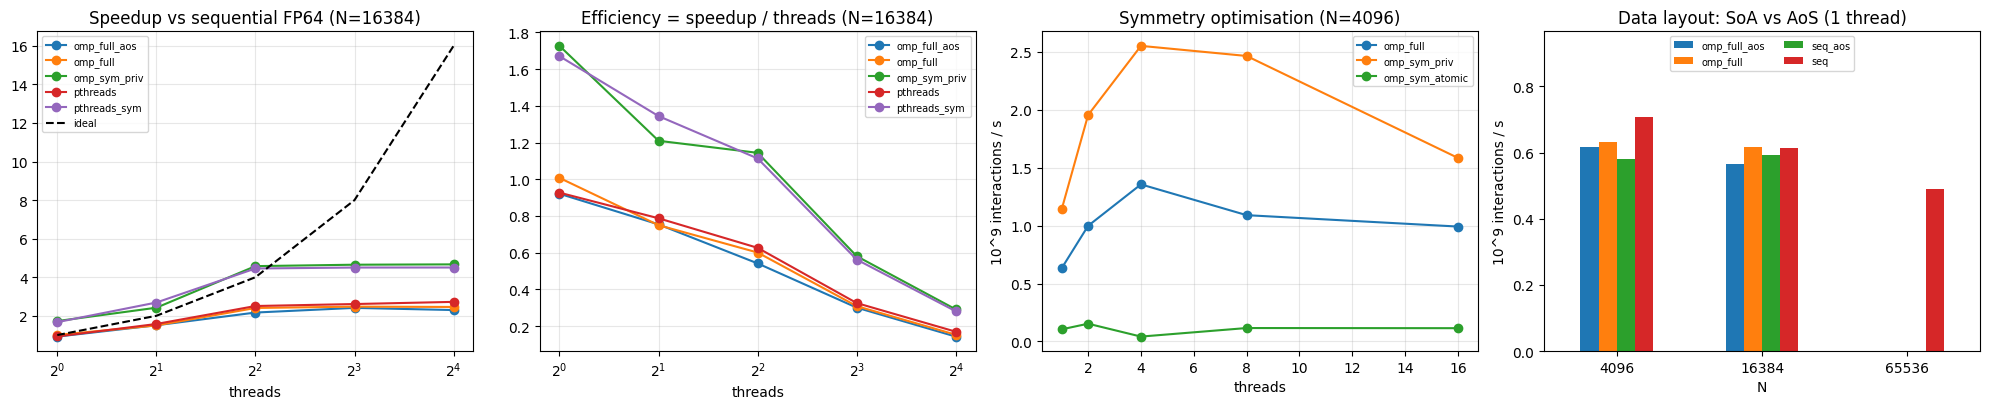

In [11]:
# B7 - Team 17 charts. Uses the table `g` from B6 (FP64 variants, baseline = seq FP64 at the same N).
import matplotlib.pyplot as plt
f = g[g.implementation.str.endswith('fp64') & ~g.implementation.str.startswith('seq')]
N = f['size'].max()                                                   # largest N for speedup / efficiency
Nsym = g[g.implementation == 'omp_sym_atomic_fp64']['size'].max()     # largest N that has the atomic variant too
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for imp, d in f[f['size'] == N].groupby('implementation'):
    ax[0].plot(d.threads_or_ranks, d.speedup,    'o-', label=imp[:-5])
    ax[1].plot(d.threads_or_ranks, d.efficiency, 'o-', label=imp[:-5])
th = sorted(f.threads_or_ranks.unique()); ax[0].plot(th, th, 'k--', label='ideal')
ax[0].set_title(f'Speedup vs sequential FP64 (N={N})'); ax[1].set_title(f'Efficiency = speedup / threads (N={N})')
for imp in ['omp_full_fp64', 'omp_sym_priv_fp64', 'omp_sym_atomic_fp64']:        # effect of Newton's 3rd law
    d = f[(f['size'] == Nsym) & (f.implementation == imp)]; ax[2].plot(d.threads_or_ranks, d.Ginter_s, 'o-', label=imp[:-5])
ax[2].set_title(f"Symmetry optimisation (N={Nsym})"); ax[2].set_ylabel('10^9 interactions / s')
lay = g[(g.threads_or_ranks == 1) & g.implementation.isin(['seq_fp64', 'seq_aos_fp64', 'omp_full_fp64', 'omp_full_aos_fp64'])]
lay.pivot(index='size', columns='implementation', values='Ginter_s').rename(columns=lambda c: c[:-5]).plot.bar(ax=ax[3], rot=0)
ax[3].legend(fontsize=7, ncol=2, loc='upper center'); ax[3].set_ylim(0, ax[3].get_ylim()[1] * 1.3); ax[3].set_title('Data layout: SoA vs AoS (1 thread)'); ax[3].set_ylabel('10^9 interactions / s'); ax[3].set_xlabel('N')
for k in (0, 1, 2): ax[k].set_xlabel('threads'); ax[k].grid(alpha=.3); ax[k].legend(fontsize=7)
ax[0].set_xscale('log', base=2); ax[1].set_xscale('log', base=2)
plt.tight_layout(); plt.savefig('nbody_work/results/team17_corrected_charts.png', dpi=130); plt.show()

🖥️ **[RUN ON YOUR LOCAL PC]**

## Part C – Team 18 · Problem 18 · Distributed N-body (MPI)
**Variants:** `allgather` (MPI_Allgather of all positions every step – baseline) · `ring` (blocks passed round the ring p−1 times with `MPI_Sendrecv_replace`) · `ring_overlap` (double-buffered `MPI_Isend/Irecv`, next block in flight while the current block is computed).
`N` must be divisible by the number of ranks. Not included: the *optional* 2-D force decomposition.
In the CSV: `kernel_ms` = force computation, `transfer_ms` = MPI communication (max over ranks) → ratio `transfer_ms / kernel_ms` = communication-to-computation ratio.

Steps: **C1** code → **C2** compile → **C3** verify → **C4** strong scaling → **C5** weak scaling → **C6** summary.

🖥️ **[RUN ON YOUR LOCAL PC]**  **C1 – source code**

In [43]:
%%writefile nbody_work/nbody_mpi.cpp
// =============================================================================
//  Team 18 / Problem 18 : Distributed N-body with MPI
//
//  Each rank owns n = N/p particles (N must be divisible by p).
//  variants (--variant):
//    allgather     MPI_Allgather of all positions every step               <- baseline
//    ring          ring exchange: blocks are passed to the next rank p-1 times
//                  (MPI_Sendrecv_replace), forces accumulated as blocks arrive
//    ring_overlap  ring with double buffering: MPI_Isend/Irecv of the NEXT block
//                  overlaps with the force computation on the CURRENT block
//  precision (--prec): fp64 | fp32 | mixed
//
//  Timing columns written to the CSV:
//     kernel_ms   = force-computation time (max over ranks)
//     transfer_ms = MPI communication time (max over ranks); for ring_overlap this is only the
//                   *exposed* (non-hidden) communication = posting + waiting time
// =============================================================================
#include "nbody_common.hpp"
#include <mpi.h>

using namespace nb;

template <class S> MPI_Datatype mpi_type();
template <> MPI_Datatype mpi_type<float>()  { return MPI_FLOAT;  }
template <> MPI_Datatype mpi_type<double>() { return MPI_DOUBLE; }

template <class M>
struct MpiSim {
    typedef typename M::S S;
    int N, n, rank, p; std::string variant; MPI_Comm comm = MPI_COMM_WORLD;
    std::vector<S> x, y, z, vx, vy, vz, ax, ay, az;   // local particles
    std::vector<S> mall;                               // masses of ALL particles (replicated, never changes)
    std::vector<S> blk0, blk1, posall;                 // 3n-long position blocks [x(n) y(n) z(n)]; posall = p*3n
    double t_comp = 0, t_comm = 0;

    MpiSim(int N_, const std::string& v) : N(N_), variant(v) {
        MPI_Comm_rank(comm, &rank); MPI_Comm_size(comm, &p);
        if (v != "allgather" && v != "ring" && v != "ring_overlap") {
            if (rank == 0) fprintf(stderr, "unknown variant '%s'\n", v.c_str());
            MPI_Abort(comm, 1);
        }
        if (N % p != 0) {
            if (rank == 0) fprintf(stderr, "N=%d must be divisible by the number of ranks %d\n", N, p);
            MPI_Abort(comm, 1);
        }
        n = N / p;
        x.resize(n); y.resize(n); z.resize(n); vx.resize(n); vy.resize(n); vz.resize(n);
        ax.resize(n); ay.resize(n); az.resize(n); mall.resize(N);
        blk0.resize(3 * n); blk1.resize(3 * n); posall.resize((size_t)3 * N);
    }
    bool is_root() const { return rank == 0; }
    std::string impl() const { return variant + "_" + M::name(); }
    int par() const { return p; }
    void sync() { MPI_Barrier(comm); }
    void finalize() {}
    std::string notes() {
        char b[200]; snprintf(b, sizeof b, "MPI ranks=%d, particles per rank=%d, comm/comp ratio (last run, max over ranks) = %.3f", p, n, last_ratio);
        return b;
    }
    double last_ratio = 0;
    Timing timing() {
        double mine[2] = {t_comp, t_comm}, mx[2] = {0, 0};
        MPI_Reduce(mine, mx, 2, MPI_DOUBLE, MPI_MAX, 0, comm);
        Timing t; t.kernel_ms = mx[0]; t.transfer_ms = mx[1];
        last_ratio = mx[0] > 0 ? mx[1] / mx[0] : 0;
        return t;
    }

    void load(const Particles& ic) {
        const int o = rank * n;
        for (int i = 0; i < n; ++i) {
            x[i] = (S)ic.x[o + i]; y[i] = (S)ic.y[o + i]; z[i] = (S)ic.z[o + i];
            vx[i] = (S)ic.vx[o + i]; vy[i] = (S)ic.vy[o + i]; vz[i] = (S)ic.vz[o + i];
        }
        for (int i = 0; i < N; ++i) mall[i] = (S)ic.m[i];
        md = ic.m;
        compute_forces();
        t_comp = t_comm = 0;
    }
    std::vector<double> md;

    void pack(std::vector<S>& b) {
        for (int i = 0; i < n; ++i) { b[i] = x[i]; b[n + i] = y[i]; b[2 * n + i] = z[i]; }
    }
    // add the pull of one source block (3n positions, n masses) onto all local particles
    void accumulate(const S* bp, const S* bm) {
        for (int i = 0; i < n; ++i) {
            S a = ax[i], b = ay[i], c = az[i];
            accel_one<M>(x[i], y[i], z[i], n, bp, bp + n, bp + 2 * n, bm, a, b, c);
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    void zero_acc() { for (int i = 0; i < n; ++i) { ax[i] = 0; ay[i] = 0; az[i] = 0; } }

    void compute_forces() {
        const MPI_Datatype T = mpi_type<S>();
        const int right = (rank + 1) % p, left = (rank - 1 + p) % p;
        zero_acc();
        if (variant == "allgather") {
            pack(blk0);
            double t0 = now_ms();
            MPI_Allgather(blk0.data(), 3 * n, T, posall.data(), 3 * n, T, comm);
            double t1 = now_ms();
            for (int b = 0; b < p; ++b) accumulate(posall.data() + (size_t)b * 3 * n, mall.data() + (size_t)b * n);
            double t2 = now_ms();
            t_comm += t1 - t0; t_comp += t2 - t1;
        } else if (variant == "ring") {
            pack(blk0);
            for (int k = 0; k < p; ++k) {
                const int src = ((rank - k) % p + p) % p;           // owner of the block we hold now
                double t0 = now_ms();
                accumulate(blk0.data(), mall.data() + (size_t)src * n);
                double t1 = now_ms(); t_comp += t1 - t0;
                if (k < p - 1) {
                    MPI_Sendrecv_replace(blk0.data(), 3 * n, T, right, 7, left, 7, comm, MPI_STATUS_IGNORE);
                    t_comm += now_ms() - t1;
                }
            }
        } else {  // ring_overlap
            std::vector<S>* buf[2] = {&blk0, &blk1};
            pack(blk0);
            for (int k = 0; k < p; ++k) {
                std::vector<S>& cur = *buf[k & 1]; std::vector<S>& nxt = *buf[(k & 1) ^ 1];
                const int src = ((rank - k) % p + p) % p;
                MPI_Request rq[2]; double tc = 0;
                if (k < p - 1) {
                    double t0 = now_ms();
                    MPI_Irecv(nxt.data(), 3 * n, T, left, 8, comm, &rq[0]);
                    MPI_Isend(cur.data(), 3 * n, T, right, 8, comm, &rq[1]);
                    tc += now_ms() - t0;
                }
                double t1 = now_ms();
                accumulate(cur.data(), mall.data() + (size_t)src * n);      // compute while messages are in flight
                double t2 = now_ms(); t_comp += t2 - t1;
                if (k < p - 1) { MPI_Waitall(2, rq, MPI_STATUSES_IGNORE); tc += now_ms() - t2; }
                t_comm += tc;
            }
        }
    }

    void advance(int steps) {
        const S dt = (S)DT, hdt = (S)(0.5 * DT);
        for (int s = 0; s < steps; ++s) {
            for (int i = 0; i < n; ++i) {
                vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
                x[i] += dt * vx[i];   y[i] += dt * vy[i];   z[i] += dt * vz[i];
            }
            compute_forces();
            for (int i = 0; i < n; ++i) { vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i]; }
        }
    }

    void gather_one(const std::vector<S>& src, std::vector<double>& dst) {
        std::vector<double> tmp(n); for (int i = 0; i < n; ++i) tmp[i] = (double)src[i];
        if (rank == 0) dst.resize(N);
        MPI_Gather(tmp.data(), n, MPI_DOUBLE, dst.data(), n, MPI_DOUBLE, 0, comm);
    }
    bool gather(Particles& o) {
        o.n = N; o.m = md;
        gather_one(x, o.x); gather_one(y, o.y); gather_one(z, o.z);
        gather_one(vx, o.vx); gather_one(vy, o.vy); gather_one(vz, o.vz);
        return rank == 0;
    }
    bool gather_accel(std::vector<double>& a, std::vector<double>& b, std::vector<double>& c) {
        gather_one(ax, a); gather_one(ay, b); gather_one(az, c);
        return rank == 0;
    }
};

template <class M>
int run(const Args& a) {
    int rank; MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    std::string v = a.str("variant", "ring");
    int n = a.i("n", 4096);
    MpiSim<M> sim(n, v);
    if (rank == 0) printf("CONFIG  variant=%s prec=%s N=%d steps=%d ranks=%d\n", v.c_str(), M::name(), n, a.i("steps", 100), sim.p);
    return drive(sim, a, 18, "cpu_mpi", M::name());
}

int main(int argc, char** argv) {
    MPI_Init(&argc, &argv);
    Args a(argc, argv);
    std::string p = lower(a.str("prec", "fp64"));
    int rc = 1;
    if (p == "fp64")       rc = run<M64>(a);
    else if (p == "fp32")  rc = run<M32>(a);
    else if (p == "mixed") rc = run<MMix>(a);
    else fprintf(stderr, "--prec must be fp64, fp32 or mixed\n");
    MPI_Finalize();
    return rc;
}

Overwriting nbody_work/nbody_mpi.cpp


🖥️ **[RUN ON YOUR LOCAL PC]**  **C2 – compile**

In [44]:
import subprocess
import os

env = os.environ.copy()
env.update({
    "TERM": "dumb",
    "COLUMNS": "120",
    "LINES": "40"
})

cmd = """
cd "nbody_work"

unset TERMCAP

mpicxx -O3 -march=native -fno-math-errno -fopenmp-simd -std=c++17 nbody_mpi.cpp -o nbody_mpi && echo "built ./nbody_mpi"
"""

subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    env=env,
    check=True
)

CompletedProcess(args=['wsl', 'bash', '-lc', '\ncd "nbody_work"\n\nunset TERMCAP\n\nmpicxx -O3 -march=native -fno-math-errno -fopenmp-simd -std=c++17 nbody_mpi.cpp -o nbody_mpi && echo "built ./nbody_mpi"\n'], returncode=0)

🖥️ **[RUN ON YOUR LOCAL PC]**  **C3 – verify** (1, 2, 4 and 8 ranks; ranks > cores are oversubscribed, which is fine for correctness)

In [55]:

import subprocess

# WSL paths
wsl_dir = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"
results_dir = wsl_dir + "/results"
csv_file = results_dir + "/v18.csv"

# MPI verification settings
precisions = ["fp64", "fp32", "mixed"]
variants = ["allgather", "ring", "ring_overlap"]
ranks_list = [1, 2, 4, 8]

# Create results directory INSIDE WSL
setup = subprocess.run(
    [
        "wsl.exe", "bash", "-lc",
        f"mkdir -p '{results_dir}'"
    ],
    capture_output=True,
    text=True
)

if setup.returncode != 0:
    raise RuntimeError(setup.stderr)

print("Connected to WSL")
print("Results directory:", results_dir)
print("CSV file:", csv_file)
print("=" * 80)

# Run MPI tests
for P in precisions:
    for V in variants:
        for R in ranks_list:

            command = (
                f"cd '{wsl_dir}' && "
                f"mpirun -np {R} ./nbody_mpi "
                f"--variant {V} "
                f"--prec {P} "
                f"--n 1024 "
                f"--steps 5 "
                f"--runs 1 "
                f"--csv '{csv_file}'"
            )

            result = subprocess.run(
                ["wsl.exe", "bash", "-lc", command],
                capture_output=True,
                text=True
            )

            print(f"\nPrecision={P} | Variant={V} | Ranks={R}")

            if result.returncode != 0:
                print("ERROR:")
                print(result.stderr)
                continue

            verify_lines = [
                line for line in result.stdout.splitlines()
                if "VERIFY" in line
            ]

            for line in verify_lines:
                try:
                    error = float(line.split()[-1])
                    status = "PASS" if error < 1e-5 else "**CHECK**"
                except (ValueError, IndexError):
                    status = "CHECK"

                print(line, status)

print("\n" + "=" * 80)
print("All MPI verification tests completed.")
print("CSV saved at:", csv_file)


Connected to WSL
Results directory: /mnt/c/Users/johnf/Downloads/map code/nbody_work/results
CSV file: /mnt/c/Users/johnf/Downloads/map code/nbody_work/results/v18.csv

Precision=fp64 | Variant=allgather | Ranks=1
VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Precision=fp64 | Variant=allgather | Ranks=2
VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.048e-15 PASS

Precision=fp64 | Variant=allgather | Ranks=4
VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.823e-15 PASS

Precision=fp64 | Variant=allgather | Ranks=8
VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.547e-15 PASS

Precision=fp64 | Variant=ring | Ranks=1
VERIFY  impl=ring_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00 PASS

Precision=fp64 | Variant=ring | Ranks=2
VERIFY  impl=ring_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.048e-15 PASS

Precision=fp64 | Variant=ring | Ranks=4
VERIFY  impl=ring_f

🖥️ **[RUN ON YOUR LOCAL PC]**  **C4 – strong scaling** (brief: 1, 2, 4, 8, 16 ranks; 100 steps; two values of N). Ranks above your core count are oversubscribed – their communication time then includes waiting for other ranks, so mention your core count in the report. Add `65536` to the N list if you have time (it is slow).

In [1]:

import subprocess

# WSL working directory
wsl_dir = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

# Results output
results_dir = wsl_dir + "/results"
csv_file = results_dir + "/team18.csv"

# Experiment settings
STEPS = 100
RANKS = [1, 2, 4, 8, 16]
PARTICLES = [4096, 16384]
VARIANTS = ["allgather", "ring", "ring_overlap"]

# Create results directory and clear previous CSV
setup_command = (
    f"mkdir -p '{results_dir}' && "
    f"rm -f '{csv_file}'"
)

subprocess.run(
    ["wsl.exe", "bash", "-lc", setup_command],
    check=True
)

print("Connecting to WSL...")
print("Output:", csv_file)
print("=" * 80)

# Run MPI experiments
for N in PARTICLES:
    for V in VARIANTS:
        for R in RANKS:

            command = (
                f"cd '{wsl_dir}' && "
                f"mpirun --oversubscribe -np {R} ./nbody_mpi "
                f"--variant {V} "
                f"--prec fp64 "
                f"--n {N} "
                f"--steps {STEPS} "
                f"--csv '{csv_file}'"
            )

            result = subprocess.run(
                ["wsl.exe", "bash", "-lc", command],
                capture_output=True,
                text=True
            )

            print(f"\nN={N} | Variant={V} | Ranks={R}")

            if result.returncode != 0:
                print("ERROR:")
                print(result.stderr)
                continue

            for line in result.stdout.splitlines():
                if "RESULT" in line:
                    print(line)

print("\n" + "=" * 80)
print("All experiments completed.")
print("CSV saved at:", csv_file)


Connecting to WSL...
Output: /mnt/c/Users/johnf/Downloads/map code/nbody_work/results/team18.csv

N=4096 | Variant=allgather | Ranks=1
RESULT  allgather_fp64               N=4096    steps=100   par=1   total_ms=3106.69+-500.74  Ginteractions/s=0.5501+-0.0786  GFLOP/s(20 flop/int)=11.00  [5 timed runs]

N=4096 | Variant=allgather | Ranks=2
RESULT  allgather_fp64               N=4096    steps=100   par=2   total_ms=1941.74+-68.13  Ginteractions/s=0.8649+-0.0306  GFLOP/s(20 flop/int)=17.30  [5 timed runs]

N=4096 | Variant=allgather | Ranks=4
RESULT  allgather_fp64               N=4096    steps=100   par=4   total_ms=1286.59+-135.71  Ginteractions/s=1.3154+-0.1352  GFLOP/s(20 flop/int)=26.31  [5 timed runs]

N=4096 | Variant=allgather | Ranks=8
RESULT  allgather_fp64               N=4096    steps=100   par=8   total_ms=2191.98+-68.76  Ginteractions/s=0.7660+-0.0237  GFLOP/s(20 flop/int)=15.32  [5 timed runs]

N=4096 | Variant=allgather | Ranks=16
RESULT  allgather_fp64               N=409

🖥️ **[RUN ON YOUR LOCAL PC]**  **C5 – weak scaling** (work per rank constant ⇒ N = N₀·√p, rounded to a multiple of p)

In [11]:

import subprocess
import os
import math

# WSL project directory
wsl_dir = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

# CSV output
csv_file = f"{wsl_dir}/results/team18_weak.csv"

# Experiment settings
STEPS = 100
N0 = 2048

variants = ["allgather", "ring", "ring_overlap"]
ranks_list = [1, 2, 4, 8, 16]

env = os.environ.copy()
env.update({
    "TERM": "dumb",
    "COLUMNS": "120",
    "LINES": "40"
})

print("Connecting to WSL...")

# Create results directory
setup = subprocess.run(
    [
        "wsl.exe", "bash", "-lc",
        f"mkdir -p '{wsl_dir}/results' && cd '{wsl_dir}' && test -x ./nbody_mpi"
    ],
    capture_output=True,
    text=True
)

if setup.returncode != 0:
    print("WSL SETUP FAILED:")
    print(setup.stderr)
    raise RuntimeError("Could not access project or executable.")

# Remove previous CSV
subprocess.run(
    ["wsl.exe", "bash", "-lc", f"rm -f '{csv_file}'"],
    check=True
)

print("Output:", csv_file)
print("=" * 80)

completed = 0
failed = 0
total = len(variants) * len(ranks_list)

for V in variants:
    for R in ranks_list:

        # Weak scaling: approximately constant work per rank
        N = round(N0 * math.sqrt(R) / R) * R

        print(f"\n[{completed + failed + 1}/{total}] "
              f"Variant={V} | Ranks={R} | N={N}")

        command = [
            "wsl.exe",
            "bash",
            "-lc",
            (
                f"cd '{wsl_dir}' && "
                f"mpirun --oversubscribe -np {R} "
                f"./nbody_mpi "
                f"--variant {V} "
                f"--prec fp64 "
                f"--n {N} "
                f"--steps {STEPS} "
                f"--csv 'results/team18_weak.csv'"
            )
        ]

        result = subprocess.run(
            command,
            env=env,
            capture_output=True,
            text=True
        )

        # Display RESULT lines
        for line in result.stdout.splitlines():
            if "RESULT" in line:
                print(line)

        if result.returncode == 0:
            completed += 1
            print("STATUS: SUCCESS")
        else:
            failed += 1
            print("STATUS: FAILED")
            print("Exit code:", result.returncode)
            print("STDOUT:")
            print(result.stdout[-3000:])
            print("STDERR:")
            print(result.stderr[-3000:])

print("\n" + "=" * 80)
print("WEAK SCALING EXPERIMENT SUMMARY")
print("=" * 80)

print(f"Completed: {completed}/{total}")
print(f"Failed:    {failed}/{total}")
print("CSV:", csv_file)

# Verify CSV exists
check = subprocess.run(
    ["wsl.exe", "bash", "-lc",
     f"ls -lh '{csv_file}'"],
    capture_output=True,
    text=True
)

print("\nCSV FILE CHECK:")
print(check.stdout if check.returncode == 0 else check.stderr)


Connecting to WSL...
Output: /mnt/c/Users/johnf/Downloads/map code/nbody_work/results/team18_weak.csv

[1/15] Variant=allgather | Ranks=1 | N=2048
RESULT  allgather_fp64               N=2048    steps=100   par=1   total_ms=589.93+-16.88  Ginteractions/s=0.7114+-0.0197  GFLOP/s(20 flop/int)=14.23  [5 timed runs]
STATUS: SUCCESS

[2/15] Variant=allgather | Ranks=2 | N=2896
RESULT  allgather_fp64               N=2896    steps=100   par=2   total_ms=1132.72+-184.37  Ginteractions/s=0.7546+-0.1100  GFLOP/s(20 flop/int)=15.09  [5 timed runs]
STATUS: SUCCESS

[3/15] Variant=allgather | Ranks=4 | N=4096
RESULT  allgather_fp64               N=4096    steps=100   par=4   total_ms=1895.61+-166.57  Ginteractions/s=0.8906+-0.0797  GFLOP/s(20 flop/int)=17.81  [5 timed runs]
STATUS: SUCCESS

[4/15] Variant=allgather | Ranks=8 | N=5792
RESULT  allgather_fp64               N=5792    steps=100   par=8   total_ms=4074.44+-125.95  Ginteractions/s=0.8240+-0.0245  GFLOP/s(20 flop/int)=16.48  [5 timed runs]


🖥️ **[RUN ON YOUR LOCAL PC]**  **C6 – summary: speedup, efficiency, communication/computation ratio**

In [12]:

import pandas as pd
import os

# Absolute path to your results folder
csv_file = r"C:\Users\johnf\Downloads\map code\nbody_work\results\team18.csv"

# Check that the file exists
print("File exists:", os.path.exists(csv_file))

# Load CSV
d = pd.read_csv(csv_file)

# Aggregate results
g = (
    d.groupby(['size', 'implementation', 'threads_or_ranks'])
    .agg(
        total_ms=('total_ms', 'mean'),
        comp_ms=('kernel_ms', 'mean'),
        comm_ms=('transfer_ms', 'mean')
    )
    .reset_index()
)

# Communication/computation ratio
g['comm_over_comp'] = g.comm_ms / g.comp_ms

# Speedup relative to 1 thread/rank
t1 = (
    g[g.threads_or_ranks == 1]
    .set_index(['size', 'implementation'])['total_ms']
)

g['speedup'] = g.apply(
    lambda r: t1.get(
        (r['size'], r['implementation']), float('nan')
    ) / r.total_ms,
    axis=1
)

# Parallel efficiency
g['efficiency'] = g.speedup / g.threads_or_ranks

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

display(g.round(3))


File exists: True


,size,implementation,threads_or_ranks,total_ms,comp_ms,comm_ms,comm_over_comp,speedup,efficiency
0,4096,allgather_fp64,1,3106.694,3102.040,0.742,0.000,1.000,1.000
1,4096,allgather_fp64,2,1941.745,1910.141,41.685,0.022,1.600,0.800
2,4096,allgather_fp64,4,1286.593,1184.350,170.776,0.144,2.415,0.604
3,4096,allgather_fp64,8,2191.977,1382.493,951.344,0.688,1.417,0.177
4,4096,allgather_fp64,16,2855.834,2267.288,2185.179,0.964,1.088,0.068
5,4096,ring_fp64,1,2742.378,2738.792,0.000,0.000,1.000,1.000
6,4096,ring_fp64,2,1721.706,1696.023,29.340,0.017,1.593,0.796
7,4096,ring_fp64,4,1539.565,1316.043,313.804,0.238,1.781,0.445
8,4096,ring_fp64,8,2428.743,1325.641,1367.810,1.032,1.129,0.141
9,4096,ring_fp64,16,3242.549,2166.573,2806.322,1.295,0.846,0.053


🖥️ **[RUN ON YOUR LOCAL PC]**  **C7 – Team 18 charts** (strong/weak scaling, communication-to-computation ratio)

WEAK SCALING RESULTS


,implementation,threads_or_ranks,total_ms,N,weak_efficiency
0,allgather_fp64,1,589.931,2048,1.000
1,allgather_fp64,2,1132.721,2896,0.521
2,allgather_fp64,4,1895.609,4096,0.311
3,allgather_fp64,8,4074.435,5792,0.145
4,allgather_fp64,16,9029.175,8192,0.065
5,ring_fp64,1,766.527,2048,1.000
6,ring_fp64,2,899.165,2896,0.852
7,ring_fp64,4,1392.204,4096,0.551
8,ring_fp64,8,5036.158,5792,0.152
9,ring_fp64,16,10088.250,8192,0.076


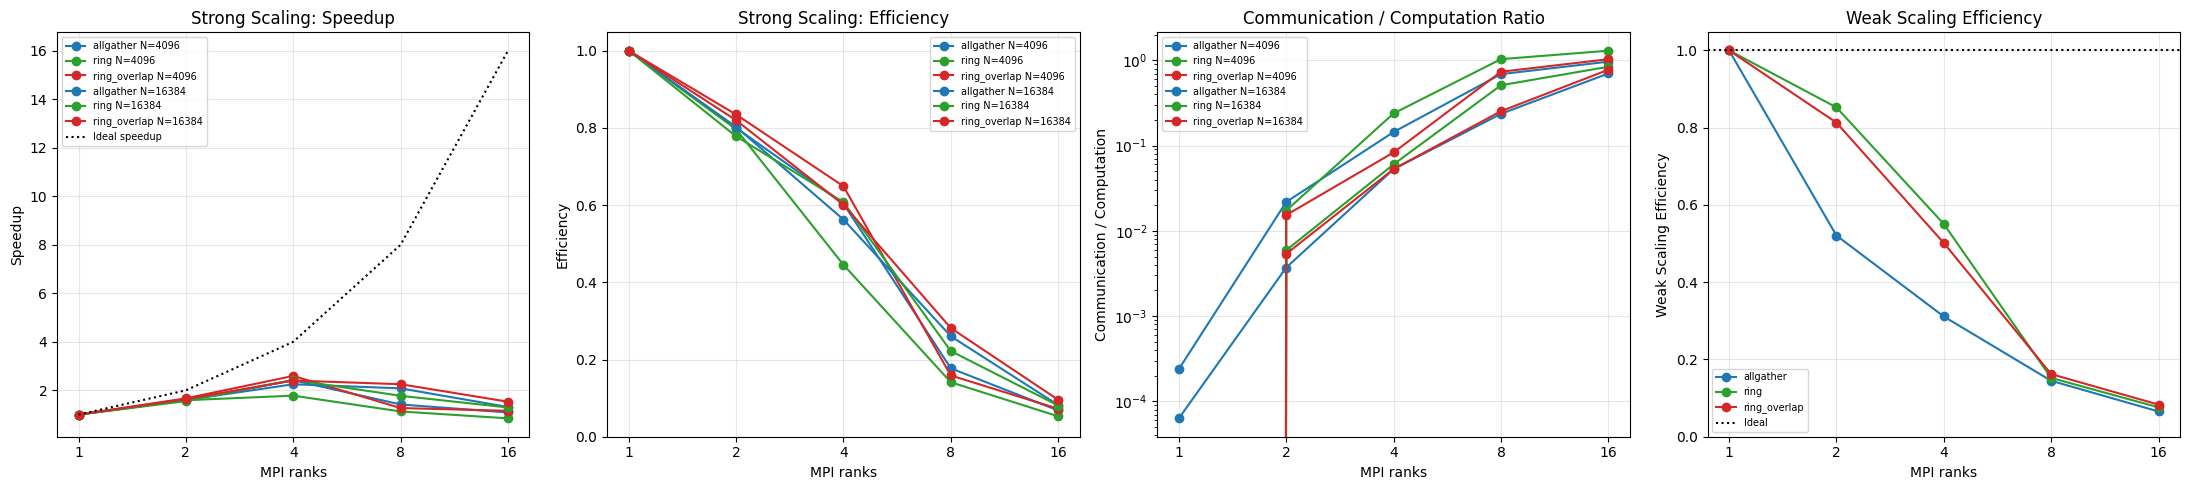


Charts successfully saved!
Location: C:\Users\johnf\Downloads\map code\nbody_work\results\team18_charts.png

NOTE: MPI ranks beyond the physical CPU core count may be oversubscribed. Mention this in the report.


In [14]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Project directory (Windows path)
project_dir = r"C:\Users\johnf\Downloads\map code\nbody_work"
results_dir = os.path.join(project_dir, "results")

# --------------------------------------------------
# 1. Load weak-scaling results
# --------------------------------------------------

weak_file = os.path.join(results_dir, "team18_weak.csv")

w_raw = pd.read_csv(weak_file)

w = (
    w_raw.groupby(["implementation", "threads_or_ranks"])
    .agg(
        total_ms=("total_ms", "mean"),
        N=("size", "first")
    )
    .reset_index()
)

# Calculate weak-scaling efficiency
w["weak_efficiency"] = w.apply(
    lambda r:
        w[
            (w.implementation == r.implementation) &
            (w.threads_or_ranks == 1)
        ].total_ms.iloc[0] / r.total_ms,
    axis=1
)

print("WEAK SCALING RESULTS")
display(w.round(3))

# --------------------------------------------------
# 2. Plot configuration
# --------------------------------------------------

col = {
    "allgather_fp64": "tab:blue",
    "ring_fp64": "tab:green",
    "ring_overlap_fp64": "tab:red"
}

fig, ax = plt.subplots(1, 4, figsize=(22, 5))

# --------------------------------------------------
# 3. Strong-scaling charts (C6 table g)
# --------------------------------------------------

for (N, imp), d in g.groupby(["size", "implementation"]):

    lab = f"{imp[:-5]} N={N}"

    ax[0].plot(
        d.threads_or_ranks,
        d.speedup,
        "o-",
        color=col[imp],
        label=lab
    )

    ax[1].plot(
        d.threads_or_ranks,
        d.efficiency,
        "o-",
        color=col[imp],
        label=lab
    )

    ax[2].plot(
        d.threads_or_ranks,
        d.comm_over_comp,
        "o-",
        color=col[imp],
        label=lab
    )

# Ideal speedup reference
r = sorted(g.threads_or_ranks.unique())
ax[0].plot(r, r, "k:", label="Ideal speedup")

# --------------------------------------------------
# 4. Weak-scaling chart
# --------------------------------------------------

for imp, d in w.groupby("implementation"):

    ax[3].plot(
        d.threads_or_ranks,
        d.weak_efficiency,
        "o-",
        color=col[imp],
        label=imp[:-5]
    )

# Ideal weak efficiency reference
ax[3].axhline(1.0, color="black", linestyle=":", label="Ideal")

# --------------------------------------------------
# 5. Format all charts
# --------------------------------------------------

titles = [
    "Strong Scaling: Speedup",
    "Strong Scaling: Efficiency",
    "Communication / Computation Ratio",
    "Weak Scaling Efficiency"
]

for a, title in zip(ax, titles):

    a.set_title(title)
    a.set_xlabel("MPI ranks")
    a.set_xscale("log", base=2)
    a.set_xticks([1, 2, 4, 8, 16])
    a.set_xticklabels([1, 2, 4, 8, 16])
    a.grid(alpha=0.3)
    a.legend(fontsize=7)

ax[0].set_ylabel("Speedup")
ax[1].set_ylabel("Efficiency")
ax[2].set_ylabel("Communication / Computation")
ax[3].set_ylabel("Weak Scaling Efficiency")

ax[1].set_ylim(bottom=0)
ax[3].set_ylim(bottom=0)

ax[2].set_yscale("log")

plt.tight_layout()

# --------------------------------------------------
# 6. Save chart
# --------------------------------------------------

chart_file = os.path.join(results_dir, "team18_charts.png")

plt.savefig(
    chart_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nCharts successfully saved!")
print("Location:", chart_file)

print(
    "\nNOTE: MPI ranks beyond the physical CPU core count "
    "may be oversubscribed. Mention this in the report."
)


🖥️ **[RUN ON YOUR LOCAL PC]**

## Part E (CPU half) – Team 20 accuracy runs: sequential, OpenMP, MPI
Each platform is run in FP64, FP32 and mixed for **10,000 steps** (brief), saving total energy and all positions every 100 steps into `acc/`. **N = 4096** (the smallest size in the brief). The Colab notebook must use the **same N and steps** for the GPU runs – the analysis stops with a message if they differ.

| platform tag | program | configuration |
|---|---|---|
| `seq` | `nbody_smp` | sequential (FP64 = the reference) |
| `openmp` | `nbody_smp` | `omp_full`, all cores |
| `mpi` | `nbody_mpi` | `ring`, 4 ranks |

🖥️ **[RUN ON YOUR LOCAL PC]**  **E1 – helper script**

In [15]:
%%writefile team20_run.py
#!/usr/bin/env python3
"""Team 20 : run every platform (seq, OpenMP, MPI, CUDA) in FP64 / FP32 / mixed for the accuracy study.
Each run simulates --steps steps and samples energy + positions every --every steps.
Outputs (per run, in --out):  <platform>_<prec>_energy.csv, <platform>_<prec>_traj.bin, <platform>_<prec>_results.csv"""
import argparse, os, subprocess, sys, shutil, time

ap = argparse.ArgumentParser()
ap.add_argument('--n', type=int, default=1024, help='particles (keep <=2048 on Colab for 10,000 steps)')
ap.add_argument('--steps', type=int, default=10000)
ap.add_argument('--every', type=int, default=100, help='energy/trajectory sampling interval (steps)')
ap.add_argument('--threads', type=int, default=os.cpu_count() or 2)
ap.add_argument('--ranks', type=int, default=2, help='MPI ranks (N must be divisible by it)')
ap.add_argument('--bin', default='.')
ap.add_argument('--out', default='acc')
ap.add_argument('--precs', default='fp64,fp32,mixed')
ap.add_argument('--platforms', default='seq,openmp,mpi,cuda,cuda_rsqrt',
                help='comma list from: seq,openmp,mpi,cuda,cuda_rsqrt')
a = ap.parse_args()

os.makedirs(a.out, exist_ok=True)
env = dict(os.environ, OMPI_ALLOW_RUN_AS_ROOT='1', OMPI_ALLOW_RUN_AS_ROOT_CONFIRM='1',
           OMPI_MCA_rmaps_base_oversubscribe='1', OMPI_MCA_btl_vader_single_copy_mechanism='none')
B = a.bin
def cmd_for(plat, prec):
    if plat == 'seq':    return [f'{B}/nbody_smp', '--variant', 'seq', '--threads', '1', '--prec', prec]
    if plat == 'openmp': return [f'{B}/nbody_smp', '--variant', 'omp_full', '--threads', str(a.threads), '--prec', prec]
    if plat == 'mpi':    return ['mpirun', '-np', str(a.ranks), f'{B}/nbody_mpi', '--variant', 'ring', '--prec', prec]
    if plat == 'cuda':   return [f'{B}/nbody_cuda', '--variant', 'tiled', '--block', '128', '--fast', '0', '--prec', prec]
    if plat == 'cuda_rsqrt': return [f'{B}/nbody_cuda', '--variant', 'tiled', '--block', '128', '--fast', '1', '--prec', prec]
    raise SystemExit('unknown platform ' + plat)

# the sequential FP64 run is the reference for trajectory errors -> run it first
plats = [p for p in a.platforms.split(',') if p]
if 'seq' in plats: plats.remove('seq')
plats = ['seq'] + plats
precs = a.precs.split(',')
t_all = time.time()
for plat in plats:
    if plat.startswith('cuda') and not os.path.exists(f'{B}/nbody_cuda'):
        print(f'[skip] {plat}: ./nbody_cuda not built (needs a GPU runtime)'); continue
    for prec in precs:
        tag = f'{plat}_{prec}'
        res = f'{a.out}/{tag}_results.csv'
        if os.path.exists(res): os.remove(res)
        cmd = cmd_for(plat, prec) + ['--n', str(a.n), '--steps', str(a.steps), '--energy-every', str(a.every),
                                      '--out', f'{a.out}/{tag}', '--csv', res]
        t0 = time.time()
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(f'[FAILED] {tag}\n{p.stdout}\n{p.stderr}'); sys.exit(1)
        line = [l for l in p.stdout.splitlines() if l.startswith(('VERIFY', 'ACCURACY'))]
        print(f'[{time.time()-t0:6.1f}s] {tag:18s}', ' | '.join(l.split('impl=')[-1] if l.startswith('ACCURACY') else l.split('=')[-1].strip() for l in line))
print(f'all runs finished in {time.time()-t_all:.0f}s -> {a.out}/')

Writing team20_run.py


🖥️ **[RUN ON YOUR LOCAL PC]**  **E2 – run seq, OpenMP and MPI × FP64/FP32/mixed (10,000 steps).** ~20–60 min depending on your CPU. Edit `--ranks` if you like (must divide 4096).

In [18]:
%cd "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

c:\mnt\c\Users\johnf\Downloads\map code\nbody_work


In [5]:
import subprocess

wsl_dir = "/mnt/c/Users/johnf/Downloads/map code/nbody_work"

cmd = [
    "wsl.exe",
    "--cd", wsl_dir,
    "python3",
    "../team20_run.py",
    "--bin", ".",
    "--n", "4096",
    "--steps", "10000",
    "--every", "100",
    "--ranks", "4",
    "--platforms", "seq,openmp,mpi",
    "--out", "acc"
]

result = subprocess.run(cmd, text=True)
print("Exit code:", result.returncode)

Exit code: 0


In [6]:
import subprocess

cmd = """
cd "/mnt/c/Users/johnf/Downloads/map code/nbody_work" || exit 1

echo "=== PROJECT FILES ==="
ls -lh

echo ""
echo "=== EXECUTABLES ==="
find . -maxdepth 2 -type f -name 'nbody*' -ls

echo ""
echo "=== ACCURACY OUTPUT ==="
find . -maxdepth 3 -type f \\( -name '*results.csv' -o -name '*energy.csv' -o -name '*traj.bin' \\) -ls

echo ""
echo "=== ACC DIRECTORY ==="
ls -lah acc 2>/dev/null
"""

result = subprocess.run(
    ["wsl.exe", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

=== PROJECT FILES ===
total 444K
drwxrwxrwx 1 anil anil 4.0K Nov 14 23:33 acc
-rwxrwxrwx 1 anil anil  14K Nov 14 17:10 nbody_common.hpp
-rwxrwxrwx 1 anil anil 191K Nov 14 21:05 nbody_mpi
-rwxrwxrwx 1 anil anil 8.5K Nov 14 21:04 nbody_mpi.cpp
-rwxrwxrwx 1 anil anil 158K Nov 14 17:11 nbody_smp
-rwxrwxrwx 1 anil anil  14K Nov 14 17:11 nbody_smp.cpp
drwxrwxrwx 1 anil anil 4.0K Nov 14 22:48 results
-rwxrwxrwx 1 anil anil  46K Nov 14 17:42 results.csv

=== EXECUTABLES ===
92042317384465312     16 -rwxrwxrwx   1 anil     anil        14238 Nov 14 17:10 ./nbody_common.hpp
262053203317636544    192 -rwxrwxrwx   1 anil     anil       195584 Nov 14 21:05 ./nbody_mpi
175077435514595215     12 -rwxrwxrwx   1 anil     anil         8633 Nov 14 21:04 ./nbody_mpi.cpp
140456013378724321    160 -rwxrwxrwx   1 anil     anil       161736 Nov 14 17:11 ./nbody_smp
 36591746972618222     16 -rwxrwxrwx   1 anil     anil        14056 Nov 14 17:11 ./nbody_smp.cpp

=== ACCURACY OUTPUT ===
121315714962518396     12

In [7]:
import pandas as pd
import os

folder = r"C:\Users\johnf\Downloads\map code\nbody_work\acc"

for f in sorted(os.listdir(folder)):
    if f.endswith("_results.csv") or f.endswith("_energy.csv"):
        print("\n", f)
        df = pd.read_csv(os.path.join(folder, f))
        print(df.to_string(index=False))


 mpi_fp32_energy.csv
 step  time       ke        pe      etot     rel_drift
    0   0.0 0.124086 -0.469432 -0.345346  0.000000e+00
  100   0.1 0.124945 -0.470291 -0.345346  8.044295e-09
  200   0.2 0.126903 -0.472249 -0.345346  1.478841e-08
  300   0.3 0.130051 -0.475397 -0.345346  7.193446e-09
  400   0.4 0.134506 -0.479852 -0.345346  1.411992e-08
  500   0.5 0.140366 -0.485712 -0.345346  1.753370e-08
  600   0.6 0.147843 -0.493189 -0.345346  1.739905e-08
  700   0.7 0.157123 -0.502469 -0.345346  2.498033e-08
  800   0.8 0.168477 -0.513823 -0.345346  2.307179e-08
  900   0.9 0.182222 -0.527568 -0.345346  1.614317e-08
 1000   1.0 0.198640 -0.543987 -0.345346  3.167251e-08
 1100   1.1 0.218210 -0.563556 -0.345346  2.367588e-08
 1200   1.2 0.241406 -0.586753 -0.345346  1.658140e-08
 1300   1.3 0.268670 -0.614017 -0.345346  2.336798e-09
 1400   1.4 0.300287 -0.645634 -0.345346 -2.072384e-08
 1500   1.5 0.336654 -0.682001 -0.345346 -6.069593e-08
 1600   1.6 0.378048 -0.723394 -0.345346 -7

🖥️ **[RUN ON YOUR LOCAL PC]**

### Pack the results for Colab
Creates **`local_results.zip`** (inside the `nbody_work` folder) containing `results/` (Team 17/18 CSVs) and `acc/` (the 9 CPU accuracy runs). **Upload this one file to Colab** (see the Colab notebook, step A3).

In [11]:

import zipfile, glob, os

base = "nbody_work"

files = (
    glob.glob(os.path.join(base, "results", "*")) +
    glob.glob(os.path.join(base, "acc", "*")) +
    glob.glob(os.path.join(base, "nbody_smp"))
)

with zipfile.ZipFile("local_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        if os.path.isfile(f):
            z.write(f, arcname=os.path.relpath(f, base))

print(
    len(files),
    "files packed ->",
    os.path.abspath("local_results.zip"),
    f'({os.path.getsize("local_results.zip")/1e6:.0f} MB)'
)

print(
    "nbody_smp included:",
    os.path.isfile(os.path.join(base, "nbody_smp"))
)

print(
    "acc/ runs found:",
    sorted({
        os.path.basename(f).rsplit("_", 1)[0]
        for f in glob.glob(os.path.join(base, "acc", "*_energy.csv"))
    })
)


39 files packed -> c:\Users\johnf\Downloads\map code\local_results.zip (74 MB)
nbody_smp included: True
acc/ runs found: ['mpi_fp32', 'mpi_fp64', 'mpi_mixed', 'openmp_fp32', 'openmp_fp64', 'openmp_mixed', 'seq_fp32', 'seq_fp64', 'seq_mixed']
